El propósito de esta libreta de Jupyter es analizar los distintos conjuntos de datos disponibles en el catálogo de datos abiertos del Ayuntamiento de Valencia y ver cuáles de ellos podrían ser de utilidad para este TFM, así como realizar las transformaciones necesarias para adaptarlos a nuestro caso de uso.

---

<a id="indice"></a>
<h2><font color="#5E5E5E" size=5>Índice</font></h2>

* [1. Análisis del Catálogo de Datos de OpenDataValencia](#section1)
    * [1.1. Análisis del Listado de Calles](#section2)
    * [1.2. Análisis de los Distritos](#section3)
    * [1.3. Análisis de los Barrios](#section4)
    * [1.4. Análisis de la Intensidad del Tráfico](#section5)
    * [1.5. Análisis de la Contaminación Atmosférica de la Ciudad](#section6)

* [2. Análisis Espacial y Transformaciones sobre los Datos](#section7)
    * [2.1. Análisis Espacial de los Datos](#section8)
    * [2.2. Relación Barrio-Distrito](#section9)
    * [2.3. Relación Tramo-Barrio-Distrito](#section10)
    * [2.4. Relación Tramo-Estación Ambiental](#section11)
    * [2.5. Conclusiones y Consolidación de Datasets](#section12)
    * [BONUS. Análisis de Grafos para el Cálculo de Rutas](#section13)

<a id="section1"></a>
<h2><font color="#5E5E5E" size=5>1. Análisis del Catálogo de Datos de OpenDataValencia</font></h2>

Tras la revisión de los datos disponibles en el Catálogo de Datos Abiertos, hemos encontrado cuatro datasets que pueden ser de utilidad para nuestro caso de uso y que vamos a analizar en detalle:

- **Barrios/Barris:**
Este dataset contiene en formato json los distintos barrios de la ciudad, y nos puede servir para agrupar las calles en las que vamos a analizar el tráfico y la calidad del aire por barrio con el fin de sacar estadísticas de ese barrio como medias de contaminación diarias, ver cómo de transitado es el barrio y cuáles son las calles con más tráfico y en qué momento del día, etc.
https://opendata.vlci.valencia.es/dataset/barris-barrios

- **Distritos/Districtes:**
Este dataset contiene en formato .csv los distintos distritos de la ciudad, su propósito es similar al dataset anterior, aunque aquí en lugar de usar el barrio como columna de agregación usaremos el distrito.<br>
https://opendata.vlci.valencia.es/dataset/districtes-distritos

- **Listado de las calles/Llistat dels carrers:** 
Nos va a servir par tener un callejero con todas las calles de valencia permitiéndonos así indicar el estado de cada una de ellas Abierta/Cortada
https://opendata.vlci.valencia.es/dataset/llistat-dels-carrers

- **Intensidad tráfico tramos/Intensitat transit trams:** 
Este dataset va ser el corazón de nuestro ITS, puesto que, nos va a permitir conocer el estado del tráfico en los distintos puntos de la ciudad. Además, es actualizado por el ayuntamiento de Valencia cada 3 minutos ofreciéndonos la oportunidad de utilizar datos reales y actualizados.
https://opendata.vlci.valencia.es/dataset/intensitat-transit-trams-intensidad-trafico-tramos

- **Red de vigilancia de la contaminación atmosférica/Xarxa de vigilància de la contaminació atmosfèrica:** 
De forma similar al dataset anterior, nos va a permitir conocer la calidad atmosférica en los distintos puntos de la ciudad de forma real y actualizada sin necesidad de simulaciones. La única problemática que este dataset presenta es su frecuencia de actualización de ~3 horas, que aunque es suficiente para nuestro caso de uso, no llega a tener la precisión que el dataset que vamos a utilizar para medir la intesidad del tráfico.<br>
https://opendata.vlci.valencia.es/dataset/xarxa-de-vigilancia-de-la-contaminacio-atmosferica


A continuación vamos a descargar cada uno de los datasets para analizar en mayor detalle su contenido y sus columnas, realizando así un Análisis Exploratorio de Datos más exhaustivo que el que se ofrece en la página del ayuntamiento.

`Es necesario instalar las librerías indicadas en el requirements.txt para poder visualizar el resto de celdas de este Notebook`


In [4]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import osmnx as ox
from shapely.geometry import shape, Polygon, MultiLineString
from shapely import wkt
import networkx as nx
from shapely.ops import linemerge
from shapely.geometry import MultiLineString
import pickle

sns.set_style('darkgrid')

<a id="section2"></a>
<h3><font color="#5E5E5E" size=4>1.1. Análisis del Listado de Calles</font></h3>

In [5]:
df_streets = pd.read_csv("datasets/raw/llistat-dels-carrers.csv", sep=";")
print(df_streets.info())
print(df_streets.describe())
df_streets.head()

<class 'pandas.DataFrame'>
RangeIndex: 3741 entries, 0 to 3740
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   codtipovia       3741 non-null   str  
 1   codvia           3741 non-null   int64
 2   codviacatastro   3741 non-null   int64
 3   nomoficial       3741 non-null   str  
 4   traducnooficial  3159 non-null   str  
dtypes: int64(2), str(3)
memory usage: 252.3 KB
None
              codvia  codviacatastro
count    3741.000000     3741.000000
mean   111385.446137     2114.048650
std    215826.022753     2841.616051
min        10.000000        0.000000
25%     29280.000000      551.000000
50%     58410.000000     1593.000000
75%     81327.000000     2622.000000
max    999999.000000    81672.000000


,codtipovia,codvia,codviacatastro,nomoficial,traducnooficial
0,C/,39000,3345,JOSÉ MARIA FUSTER,JOSE MARIA FUSTER
1,C/,37680,1077,JACINT LABAILA,JACINTO LABAILA
2,C/,36720,1054,IFAC,IFACH
3,C/,37110,1065,ENGINYER DICENTA,INGENIERO DICENTA
4,C/,37620,1075,JACA,JACA


La primera modificación que vamos a hacer sobre el dataset original es calcular la ubicación de cada una de las calles con el objetivo de poder identificarlas geográficamente, facilitando así la visualización de los datos de interés asociados a ellas en un mapa

In [6]:
# Descargar el callejero de Valencia y lo guardamos en un geojson (Descomentar celda la primera vez que nos lo bajemos)
G = ox.graph_from_place(
    "Valencia, España",
    network_type="drive"
)

nodes, edges = ox.graph_to_gdfs(G)
edges.to_file("datasets/raw/callejero-vlc.geojson", driver="GeoJSON")


In [7]:
gdf_callejero_vlc = gpd.read_file("datasets/raw/callejero-vlc.geojson")
print(gdf_callejero_vlc.describe())
print(gdf_callejero_vlc.info())
gdf_callejero_vlc.head()

                  u             v           key        length
count  1.457100e+04  1.457100e+04  14571.000000  14571.000000
mean   2.066905e+09  2.071047e+09      0.003637     93.619229
std    3.509769e+09  3.511534e+09      0.061332    136.834434
min    2.576729e+07  2.576729e+07      0.000000      0.274747
25%    2.376687e+08  2.438205e+08      0.000000     29.550183
50%    2.576082e+08  2.576083e+08      0.000000     60.457510
75%    1.796763e+09  1.798412e+09      0.000000    109.892670
max    1.406250e+10  1.406250e+10      2.000000   2808.123937
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 14571 entries, 0 to 14570
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   u         14571 non-null  int64   
 1   v         14571 non-null  int64   
 2   key       14571 non-null  int32   
 3   osmid     14571 non-null  object  
 4   highway   14571 non-null  object  
 5   lanes     6079 non-null   object  
 6   

/home/manu/tfm-smart-mobility-vlc/.venv/lib/python3.14/site-packages/geopandas/io/file.py:576: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


,u,v,key,osmid,highway,lanes,maxspeed,name,oneway,reversed,length,width,junction,bridge,tunnel,access,ref,geometry
0,25767293,25767446,0,5011435,[secondary],[5],[50],[Carrer de Xàtiva],True,False,79.924872,NaN,NaN,NaN,NaN,NaN,None,"LINESTRING (-0.37504 39.46713, -0.37519 39.467..."
1,25767295,35594370,0,61722188,[residential],None,None,[Plaça de l'Ajuntament],True,False,13.965293,NaN,NaN,NaN,NaN,NaN,None,"LINESTRING (-0.37682 39.46923, -0.37665 39.46922)"
2,25767295,25767450,0,5011437,[residential],[3],[30],[Avinguda del Marqués de Sotelo],True,False,102.217668,NaN,NaN,NaN,NaN,NaN,None,"LINESTRING (-0.37682 39.46923, -0.37687 39.469..."
3,25767311,25767295,0,"[803049231, 5011431]",[residential],None,[30],"[Plaça de l'Ajuntament, Carrer del Periodista ...",True,False,169.456312,9,NaN,NaN,NaN,NaN,None,"LINESTRING (-0.37865 39.46979, -0.37857 39.469..."
4,25767311,7663660953,0,"[487465952, 1074357648]",[residential],[1],[30],[Carrer de Sant Vicent Màrtir],True,False,103.812481,NaN,NaN,NaN,NaN,NaN,None,"LINESTRING (-0.37865 39.46979, -0.37863 39.469..."


Estamos viendo que este dataset de calles está mucho más completo que el ofertado en el catálogo de datos abiertos del ayuntamiento de Valencia, por lo que, en lugar de usar el que habíamos pensado en un primer momento nos vamos a quedar con este. <br>
También es apreciable que cada fila de este dataset corresponde a un tramo de la ciudad, en lugar de una calle, esto resulta muy enriquecedor para nuestro TFM, ya que, si por ejemplo hay una avenida muy larga, vamos a poder indicar que solo está cortado un tramo de esta en lugar de la avenida completa acercándonos más a un escenario real. <br>
Finalmente, destacar que tenemos columnas que nos permiten conocer la velocidad máxima en esa vía, si es de doble sentido o no y cuántos carriles hay, lo que podrían enriquecer aún más nuestro ITS.

In [8]:
# Revisar el estado de las columnas de tipo array:
# Anotación del futuro: "u","v","key","osmid" son necesarias para el cálculo de rutas
gdf_callejero_cleaned = gdf_callejero_vlc[["name","lanes","maxspeed","oneway","geometry","u","v","key","osmid","length"]]

for col in ["lanes", "maxspeed"]:
    gdf_callejero_cleaned[col] = gdf_callejero_cleaned[col].apply(
        lambda x: [] if x is None else x
    )

for col in ["lanes", "maxspeed"]:
    gdf_callejero_cleaned[f"{col}_check"] = gdf_callejero_cleaned[col].map(len)
    
print(gdf_callejero_cleaned["lanes_check"].value_counts())
print(gdf_callejero_cleaned["maxspeed_check"].value_counts())


lanes_check
0    8492
1    5927
2     140
3      11
5       1
Name: count, dtype: int64
maxspeed_check
0    10833
1     3691
2       44
3        3
Name: count, dtype: int64


In [9]:
gdf_callejero_cleaned.query("lanes_check == 3").head()


,name,lanes,maxspeed,oneway,geometry,u,v,key,osmid,length,lanes_check,maxspeed_check
2470,None,"[3, 2, 4]","[80, 50, 100]",True,"LINESTRING (-0.34364 39.48665, -0.34373 39.486...",116815522,429376790,0,"[468909344, 468909345, 468909346, 84202780]",786.351292,3,3
3636,[Avinguda de Menéndez Pidal],"[4, 7, 5]",[50],True,"LINESTRING (-0.38853 39.47977, -0.38863 39.479...",217730289,128249203,0,"[234191211, 234191212, 234191214, 41199031]",211.801918,3,1
5667,None,"[2, 3, 1]",[],True,"LINESTRING (-0.33745 39.43134, -0.33715 39.431...",254743894,5387378279,1,"[212741268, 558581654, 23524439, 558581656, 55...",846.288428,3,0
8316,None,"[2, 3, 4]","[70, 80]",True,"LINESTRING (-0.3499 39.48241, -0.34951 39.4826...",428941315,116815643,0,"[36893110, 429492850, 428764756, 428764758]",461.777562,3,2
11070,[Avinguda d'Ausiàs March],"[3, 4, 5]",[50],True,"LINESTRING (-0.36893 39.44679, -0.36911 39.447...",1850433974,1132162707,0,"[12219401, 732369439, 939463871]",382.575927,3,1


In [10]:
gdf_callejero_cleaned.query("maxspeed_check == 3").head()


,name,lanes,maxspeed,oneway,geometry,u,v,key,osmid,length,lanes_check,maxspeed_check
1942,[Circumval·lació de València],"[2, 1]","[60, 80, 100]",True,"LINESTRING (-0.35574 39.43157, -0.35508 39.431...",111992612,118001667,0,"[468909258, 468909259, 1330443181, 1330443185,...",1566.406328,2,3
2469,[Avinguda de Catalunya],"[3, 2]","[80, 50, 100]",True,"LINESTRING (-0.34364 39.48665, -0.34366 39.486...",116815522,90771153,0,"[103806071, 429492851, 36893109, 429492853, 36...",1352.481971,2,3
2470,None,"[3, 2, 4]","[80, 50, 100]",True,"LINESTRING (-0.34364 39.48665, -0.34373 39.486...",116815522,429376790,0,"[468909344, 468909345, 468909346, 84202780]",786.351292,3,3


Aunque en un primer momento se contemplara el uso de las columnas de lanes y max speed, el hecho de añadir estas va a complicar demasiado el TFM, ya que, estos campos no presentan un único valor por registro, sino que en numerosas ocasiones contienen múltiples valores asociados a una misma geometría. Esto se debe al proceso de simplificación de la red viaria realizado por OSMnx, que fusiona varios segmentos originales de OpenStreetMap en una única geometría conservando todos los valores distintos de sus atributos. Como consecuencia, no existe una correspondencia inequívoca entre dichos valores y un tramo concreto de la calle, lo que dificulta su interpretación y puede introducir ambigüedades en el análisis. <br><br>
Dado que el objetivo de este TFM no es lograr un ITS complejo si no profundizar en las técnicas de ingeniería de datos para obtener y presentar la información, se ha decidido descartar estas variables y centrar el estudio en aquellos atributos que presentan un único valor por registro y cuya semántica es inequívoca.

In [11]:
gdf_callejero_cleaned = gdf_callejero_cleaned[["name","geometry","u","v","key","osmid","length"]].rename(columns={"name": "nombre_tramo"})
gdf_callejero_cleaned.reset_index(names="tramo_osm_id", inplace=True)
gdf_callejero_cleaned["nombre_tramo"] = (
    gdf_callejero_cleaned["nombre_tramo"]
    .apply(
        lambda x: json.dumps(x.tolist(), ensure_ascii=False)
        if isinstance(x, np.ndarray)
        else None
    )
)
gdf_callejero_cleaned = gdf_callejero_cleaned.to_crs("EPSG:4326")
gdf_callejero_cleaned.to_csv(index=False,path_or_buf="datasets/working/callejero-cleaned.csv",sep=";")
gdf_callejero_cleaned

,tramo_osm_id,nombre_tramo,geometry,u,v,key,osmid,length
0,0,"[""Carrer de Xàtiva""]","LINESTRING (-0.37504 39.46713, -0.37519 39.467...",25767293,25767446,0,5011435,79.924872
1,1,"[""Plaça de l'Ajuntament""]","LINESTRING (-0.37682 39.46923, -0.37665 39.46922)",25767295,35594370,0,61722188,13.965293
2,2,"[""Avinguda del Marqués de Sotelo""]","LINESTRING (-0.37682 39.46923, -0.37687 39.469...",25767295,25767450,0,5011437,102.217668
3,3,"[""Plaça de l'Ajuntament"", ""Carrer del Periodis...","LINESTRING (-0.37865 39.46979, -0.37857 39.469...",25767311,25767295,0,"[803049231, 5011431]",169.456312
4,4,"[""Carrer de Sant Vicent Màrtir""]","LINESTRING (-0.37865 39.46979, -0.37863 39.469...",25767311,7663660953,0,"[487465952, 1074357648]",103.812481
...,...,...,...,...,...,...,...,...
14566,14566,"[""Carrer de Salvador Perles""]","LINESTRING (-0.39118 39.44283, -0.39045 39.44266)",14061065696,14061065693,0,1545964108,65.876399
14567,14567,"[""Carrer de Salvador Perles""]","LINESTRING (-0.39259 39.44317, -0.3918 39.44298)",14061065698,14061065695,0,1545964108,70.590761
14568,14568,"[""Carrer del Pintor Rafael Mocholí""]","LINESTRING (-0.36575 39.42437, -0.36547 39.42503)",14062499342,560100987,0,44063872,76.578329
14569,14569,"[""Carrer del Pintor Rafael Mocholí""]","LINESTRING (-0.36575 39.42437, -0.36583 39.424...",14062499342,3645190015,0,44063872,54.285680


<Axes: >

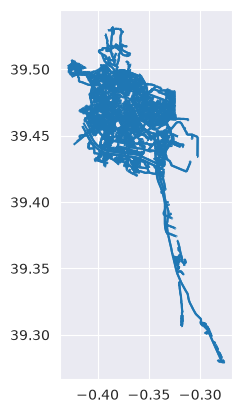

In [12]:
gdf_callejero_cleaned.plot()

<a id="section3"></a>
<h3><font color="#5E5E5E" size=4>1.2. Análisis de los Distritos</font></h3>

In [13]:
df_districts = pd.read_csv("datasets/raw/districtes-distritos.csv", sep=";")
print(df_districts.info())
print(df_districts.describe())
df_districts.head()

<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Nombre                  22 non-null     str    
 1   Código distrito         22 non-null     int64  
 2   gis.gis.DISTRITOS.area  7 non-null      float64
 3   geo_shape               22 non-null     str    
 4   geo_point_2d            22 non-null     str    
 5   latitud                 22 non-null     float64
 6   longitud                22 non-null     float64
dtypes: float64(3), int64(1), str(3)
memory usage: 251.8 KB
None
       Código distrito  gis.gis.DISTRITOS.area    latitud   longitud
count        22.000000            7.000000e+00  22.000000  22.000000
mean         10.954545            1.671029e+07  39.479437  -0.368946
std           5.760930            6.504418e+06   0.040697   0.028579
min           1.000000            2.984760e+06  39.355893  -0.417784
25%           6.250000

,Nombre,Código distrito,gis.gis.DISTRITOS.area,geo_shape,geo_point_2d,latitud,longitud
0,CIUTAT VELLA,1,16898516.25,"{""coordinates"": [[[-0.3810545927151668, 39.482...","39.474415427888424, -0.37675969658141606",39.474415,-0.376760
1,RASCANYA,15,NaN,"{""coordinates"": [[[-0.36769572194284833, 39.50...","39.49573738277865, -0.3676521651623342",39.495737,-0.367652
2,BENICALAP,16,NaN,"{""coordinates"": [[[-0.3931263029506373, 39.504...","39.4944929997908, -0.39191102614666945",39.494493,-0.391911
3,EL PLA DEL REAL,6,16927128.75,"{""coordinates"": [[[-0.3622859877164847, 39.484...","39.47456359951045, -0.3603759329955189",39.474564,-0.360376
4,POBLATS DEL SUD,19,NaN,"{""coordinates"": [[[-0.4143525635090557, 39.459...","39.35589278378015, -0.34738500202809064",39.355893,-0.347385


En este dataset podemos ver los distintos distritos de la ciudad así, como la forma geométrica que ocupan en el mapa de la ciudad. Nos va a ser de utilidad para identificar qué barrios y calles pertenecen a cada distrito, para ello vamos a transformar el dataframe a un geodataframe para posteriormente realizar las uniones espaciales pertinentes. 

In [14]:
# Revisamos que Código distrito es único
df_districts[["Código distrito"]].sort_values(by="Código distrito").value_counts()

Código distrito
17                 4
1                  1
2                  1
3                  1
4                  1
5                  1
6                  1
7                  1
8                  1
9                  1
10                 1
11                 1
12                 1
13                 1
14                 1
15                 1
16                 1
18                 1
19                 1
Name: count, dtype: int64

Tras revisar los valores de la columna distrito, vemos que hay un ID repetido, a continuación, se revisarán las filas que contienen este ID para ver a qué se debe

In [15]:
df_districts_same_id = df_districts[df_districts["Código distrito"] == 17]
df_districts_same_id

,Nombre,Código distrito,gis.gis.DISTRITOS.area,geo_shape,geo_point_2d,latitud,longitud
11,POBLATS DEL NORD,17,NaN,"{""coordinates"": [[[-0.426899715261974, 39.5623...","39.52229486062842, -0.39202139553517285",39.522295,-0.392021
12,POBLATS DEL NORD,17,NaN,"{""coordinates"": [[[-0.355087364910183, 39.5259...","39.52468048556513, -0.35945821125735933",39.524680,-0.359458
17,POBLATS DEL NORD,17,NaN,"{""coordinates"": [[[-0.3198802224479743, 39.561...","39.558805049538684, -0.3031699565111557",39.558805,-0.303170
20,POBLATS DEL NORD,17,NaN,"{""coordinates"": [[[-0.32960586149293514, 39.54...","39.544068701751755, -0.336136006684149",39.544069,-0.336136


Podemos ver que a simple vista parece que el distrito llamado POBLATS DEL NORD, está repetido. Sin embargo, si nos fijamos en las coordenadas que definen cada fila del datasets, se aprecia que estas no coinciden. Por lo que, vamos a apoyarnos de GeoPandas para ver analizar la forma espacial de este distrito.

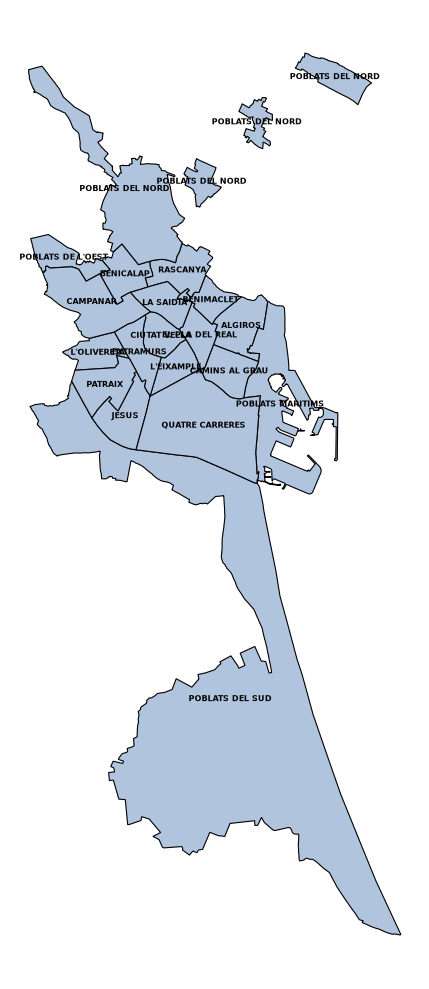

In [16]:
# Preparamos el geodataframe
df_districts["geometry"] = df_districts["geo_shape"].apply(lambda x: shape(json.loads(x)))
df_districts = df_districts[["Código distrito", "Nombre", "geometry"]].rename(
    columns={"Código distrito": "distrito_id", "Nombre": "nombre_distrito"}
)

gdf_districts = gpd.GeoDataFrame(df_districts, geometry="geometry", crs="EPSG:4326")

# Pintamos el mapa de distritos con sus nombres
fig, ax = plt.subplots(figsize=(10, 10))

gdf_districts.plot(
    ax=ax,
    color="lightsteelblue",
    edgecolor="black",
    linewidth=0.8
)

for idx, row in gdf_districts.iterrows():
    centroid = row.geometry.centroid
    ax.annotate(
        text=row["nombre_distrito"],
        xy=(centroid.x, centroid.y),
        ha="center",
        va="center",
        fontsize=6,         
        color="black",       
        fontweight="bold"   
    )

ax.set_axis_off()
plt.tight_layout()
plt.show()

Gracias al mapa de distritos podemos ver lo que ocurre, el distrito de los POBLATS DEL NORD se divide en 4 polígonos distintos. Por lo que como solución a esta situación vamos a generar un nuevo id único para cada una de las partes que formas este distrito.

In [17]:
gdf_districts["distrito_id_org"] = gdf_districts["distrito_id"].astype(int)
gdf_districts.sort_values(by="distrito_id_org", ascending=True, inplace=True)
gdf_districts["distrito_id"] = range(1, len(gdf_districts)+1)
gdf_districts.to_csv(index=False,path_or_buf="datasets/working/distritos-valencia.csv",sep=";")
gdf_districts.sort_values(by="distrito_id_org")

,distrito_id,nombre_distrito,geometry,distrito_id_org
0,1,CIUTAT VELLA,"POLYGON ((-0.38105 39.48223, -0.38023 39.48212...",1
6,2,L'EIXAMPLE,"POLYGON ((-0.36454 39.47121, -0.36378 39.47024...",2
15,3,EXTRAMURS,"POLYGON ((-0.3834 39.48116, -0.38302 39.48028,...",3
16,4,CAMPANAR,"POLYGON ((-0.42651 39.495, -0.42612 39.49507, ...",4
18,5,LA SAIDIA,"POLYGON ((-0.38947 39.48856, -0.38692 39.48916...",5
3,6,EL PLA DEL REAL,"POLYGON ((-0.36229 39.48483, -0.36284 39.48377...",6
8,7,L'OLIVERETA,"POLYGON ((-0.41293 39.46313, -0.41291 39.46316...",7
21,8,PATRAIX,"POLYGON ((-0.41435 39.45959, -0.41434 39.45963...",8
7,9,JESUS,"POLYGON ((-0.38801 39.46219, -0.38694 39.46267...",9
13,10,QUATRE CARRERES,"POLYGON ((-0.33591 39.44294, -0.33614 39.44069...",10


<a id="section4"></a>
<h3><font color="#5E5E5E" size=4>1.3. Análisis de los Barrios</font></h3>

In [18]:
json_file = "datasets/raw/barrios.json"
with open(json_file) as f:
    json_barrios = json.load(f)['features']

rows = []
for barrio in json_barrios:
    attrs = barrio['attributes']
    rows.append({
        **attrs,
        "geometry": barrio['geometry']['rings'] if 'geometry' in barrio else None
    })
df_barrios = pd.DataFrame(rows)
print(df_barrios.describe())
print(df_barrios.info())
df_barrios.head()

         objectid  gis.gis.BARRIOS.area
count   88.000000          5.600000e+01
mean   130.613636          5.027684e+06
std    171.486096          4.230242e+06
min      5.000000          2.799520e+05
25%     30.750000          2.470073e+06
50%     54.500000          3.854929e+06
75%    189.000000          6.020852e+06
max    633.000000          2.507301e+07
<class 'pandas.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   objectid              88 non-null     int64  
 1   codbarrio             88 non-null     str    
 2   nombre                88 non-null     str    
 3   coddistbar            88 non-null     str    
 4   coddistrit            88 non-null     str    
 5   gis.gis.BARRIOS.area  56 non-null     float64
 6   geometry              88 non-null     object 
dtypes: float64(1), int64(1), object(1), str(4)
memory usage: 6.3+ KB
None


,objectid,codbarrio,nombre,coddistbar,coddistrit,gis.gis.BARRIOS.area,geometry
0,63,3,LA CREU COBERTA,093,9,3.748875e+06,"[[[725320.0750000002, 4370502.608999999], [725..."
1,65,4,LA FONTETA S.LLUIS,104,10,2.388267e+06,"[[[726359.9469999997, 4369765.108999999], [726..."
2,601,5,RAFALELL-VISTABELLA,175,17,NaN,"[[[733030.1150000002, 4382084.398], [732977.89..."
3,105,2,CAMI DE VERA,142,14,NaN,"[[[727786.1529999999, 4373566.081], [727536.90..."
4,153,1,BENIMAMET,181,18,NaN,"[[[721296.5700000003, 4374871.548], [721294.21..."


La situación del dataset de los barrios es similar a la del dataset de distritos analizado en el apartado anterior, siendo interesante las columnas que indican el nombre del barrio y la región de la ciudad que ocupa. No obstante, también vemos una columna llamada coddistrit que podría ayudarnos a identificar el distrito en el que se encuentra el barrio.

Text(0.5, 0, 'ID Distrito')

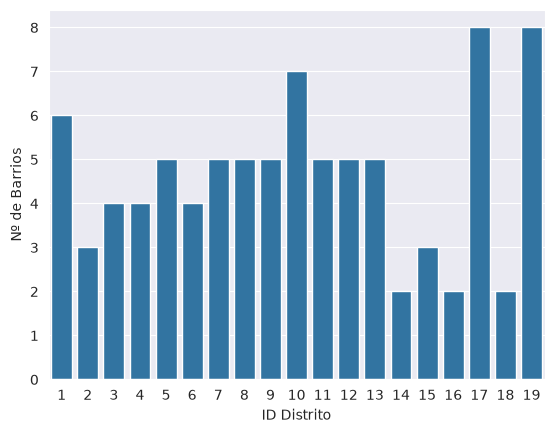

In [19]:
df_barrios["coddistrit"] = df_barrios["coddistrit"].astype(int)
sns.countplot(data=df_barrios.sort_values(by="coddistrit", ascending=True), x="coddistrit")
plt.ylabel("Nº de Barrios")
plt.xlabel("ID Distrito")

Casualmente el rango de valores en esta columna coincide con los IDs de los distritos analizados en el punto anterior. Por lo que es muy posible que esta columna se corresponda con el distrito en el que se encuentra el barrio, nos vamos a ayudar nuevamente de geopandas con el fin de confirmar esta hipótesis.

In [20]:
df_barrios["geometry"] = df_barrios["geometry"].apply(lambda rings: Polygon(rings[0]))
gdf_barrios = gpd.GeoDataFrame(
    df_barrios,
    geometry="geometry",
    crs="EPSG:25830"
)
gdf_barrios = gdf_barrios.to_crs("EPSG:4326")
gdf_barrios.reset_index(names="barrio_id", inplace=True)
gdf_barrios = gdf_barrios[["barrio_id","nombre","geometry","coddistrit"]].rename(columns={"nombre":"nombre_barrio", "coddistrit":"distrito_id"})
gdf_barrios.to_csv(index=False,path_or_buf="datasets/working/barrios-valencia.csv", sep=";")
gdf_barrios.head()

,barrio_id,nombre_barrio,geometry,distrito_id
0,0,LA CREU COBERTA,"POLYGON ((-0.38124 39.45463, -0.38281 39.44951...",9
1,1,LA FONTETA S.LLUIS,"POLYGON ((-0.36941 39.44772, -0.36826 39.44819...",10
2,2,RAFALELL-VISTABELLA,"POLYGON ((-0.28767 39.55682, -0.28829 39.55654...",17
3,3,CAMI DE VERA,"POLYGON ((-0.35156 39.48155, -0.35442 39.48244...",14
4,4,BENIMAMET,"POLYGON ((-0.42651 39.495, -0.42653 39.49506, ...",18


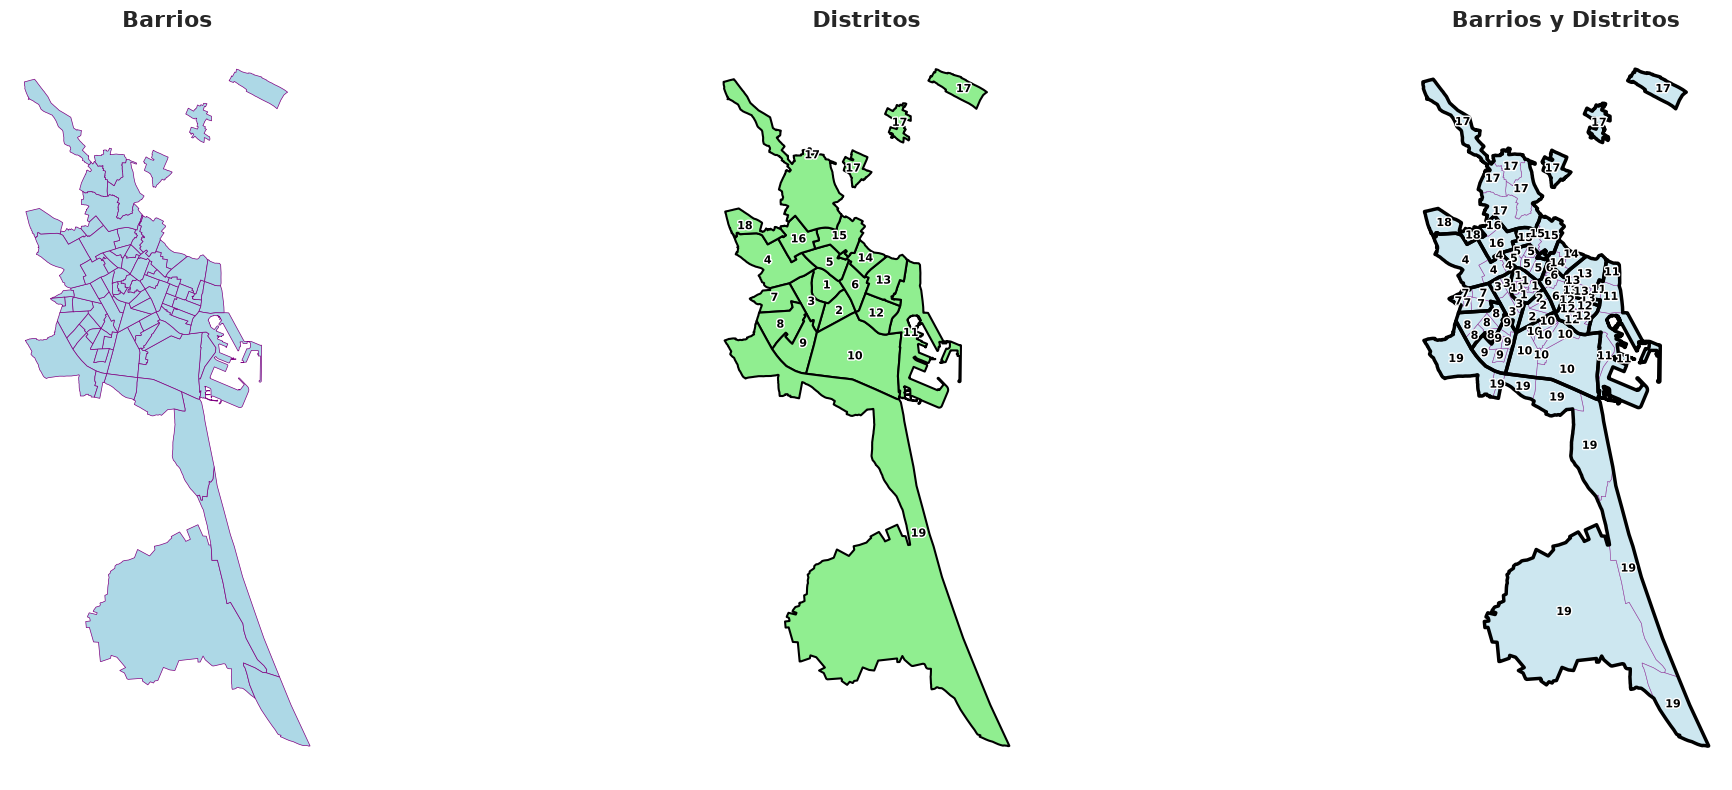

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

gdf_barrios.plot(
    ax=axes[0],
    facecolor="lightblue",
    edgecolor="purple",
    linewidth=0.5
)

axes[0].set_title("Barrios", fontsize=16, fontweight="bold")
axes[0].set_axis_off()

gdf_districts.plot(
    ax=axes[1],
    facecolor="lightgreen",
    edgecolor="black",
    linewidth=1.5
)

axes[1].set_title("Distritos", fontsize=16, fontweight="bold")
axes[1].set_axis_off()

gdf_barrios.plot(
    ax=axes[2],
    facecolor="lightblue",
    edgecolor="purple",
    linewidth=0.4,
    alpha=0.6
)

gdf_districts.plot(
    ax=axes[2],
    facecolor="none",
    edgecolor="black",
    linewidth=2.5
)

for _, row in gdf_barrios.iterrows():
    punto = row.geometry.representative_point()

    txt = axes[2].annotate(
        text=str(row["distrito_id"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=8,
        color="black",
        fontweight="bold"
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])

for _, row in gdf_districts.iterrows():
    punto = row.geometry.representative_point()

    txt = axes[1].annotate(
        text=str(row["distrito_id_org"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=8,
        color="black",
        fontweight="bold"
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])


axes[2].set_title("Barrios y Distritos", fontsize=16, fontweight="bold")
axes[2].set_axis_off()

plt.tight_layout()
plt.show()

Gracias al gráfico anterior podemos apreciar como el ID de cada distrito está asociado correctamente a cada barrio, lo cual es genial, ya que podemos usar, cada clave de unión para crear la relación distrito-barrio. No obstante, debemos tener cuidado de identificar los barrios que pertenecen al distrito POBLATS DEL NORD y asociar cada uno de ellos a la geometría en la que se encuentra.

<a id="section5"></a>
<h3><font color="#5E5E5E" size=4>1.4. Análisis de la Intensidad del Tráfico</font></h3>

In [22]:
json_file = "datasets/raw/ejemplo_estado_tráfico.json"
with open(json_file) as f:
    json_estado_traff = json.load(f)['features']

rows = []
for calle in json_estado_traff:
    attrs = calle['attributes']
    rows.append({
        **attrs,
        "geometry": calle['geometry']['paths'] if 'geometry' in calle else None
    })
df_intensidad_traff = pd.DataFrame(rows)
print(df_intensidad_traff.info())
print(df_intensidad_traff.describe())
df_intensidad_traff.head()

<class 'pandas.DataFrame'>
RangeIndex: 446 entries, 0 to 445
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   gid           446 non-null    int64  
 1   denominacion  412 non-null    str    
 2   estado        411 non-null    float64
 3   idtramo       412 non-null    float64
 4   fiwareid      443 non-null    str    
 5   geometry      412 non-null    object 
dtypes: float64(2), int64(1), object(1), str(2)
memory usage: 45.6+ KB
None
               gid      estado     idtramo
count   446.000000  411.000000  412.000000
mean   2256.080717    0.043796  272.191748
std     523.924853    0.360256  151.063834
min    1859.000000    0.000000    1.000000
25%    1972.250000    0.000000  156.500000
50%    2085.500000    0.000000  279.500000
75%    2201.750000    0.000000  392.250000
max    4316.000000    3.000000  531.000000


,gid,denominacion,estado,idtramo,fiwareid,geometry
0,1862,MARIA CRISTINA,0.0,336.0,EstadoTrafico_336,"[[[725634.7570000002, 4372463.157], [725564.89..."
1,2266,PLAÇA DEL AJUNTAMENT,NaN,335.0,EstadoTrafico_335,"[[[725653.8524000002, 4372135.939300001], [725..."
2,4313,NaN,NaN,NaN,EstadoTrafico_417,None
3,4314,NaN,NaN,NaN,EstadoTrafico_418,None
4,4315,NaN,NaN,NaN,EstadoTrafico_458,None


En el caso de este dataset podemos apreciar que no todas las filas contienen datos, por lo que hay fallos en los sistemas de medición del ayuntamiento de Valencia, no obstante, tampoco es nada preocupante, como se puede apreciar en los siguientes gráficos en los que vemos el % de nulos por columna. <br>
Simplemente a la hora de montar el pipeline, deberemos tener en cuenta esto para filtrar los posibles valores que vengan como nulos

<Axes: xlabel='None', ylabel='% de valores nulos'>

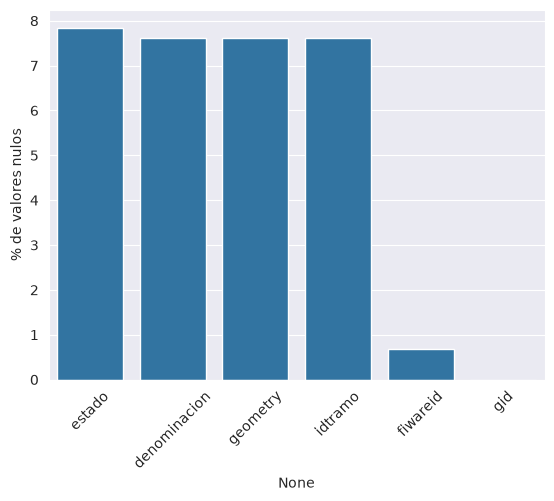

In [23]:
nulls = df_intensidad_traff.isna().mean().mul(100).sort_values(ascending=False)

plt.xticks(rotation=45)
plt.ylabel("% de valores nulos")
plt.xlabel("")
sns.barplot(x=nulls.index, y=nulls.values)

Como podemos ver en este gráfico, el porcentaje de nulos no es muy preocupante, pero vamos a eliminarlos con tal de facilitar el análisis de este dataset.

In [24]:
df_intensidad_traff_orig = df_intensidad_traff.copy()
df_intensidad_traff.dropna(subset=['estado'], inplace=True)
df_intensidad_traff = df_intensidad_traff[["gid","denominacion","estado","geometry"]].rename(columns={"denominacion":"nombre_tramo", "gid": "tramo_id"})
print(df_intensidad_traff.info())
print(df_intensidad_traff.describe())
df_intensidad_traff.head()

<class 'pandas.DataFrame'>
Index: 411 entries, 0 to 445
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   tramo_id      411 non-null    int64  
 1   nombre_tramo  411 non-null    str    
 2   estado        411 non-null    float64
 3   geometry      411 non-null    object 
dtypes: float64(1), int64(1), object(1), str(1)
memory usage: 33.3+ KB
None
          tramo_id      estado
count   411.000000  411.000000
mean   2158.459854    0.043796
std     392.564402    0.360256
min    1859.000000    0.000000
25%    1963.500000    0.000000
50%    2068.000000    0.000000
75%    2175.500000    0.000000
max    4312.000000    3.000000


,tramo_id,nombre_tramo,estado,geometry
0,1862,MARIA CRISTINA,0.0,"[[[725634.7570000002, 4372463.157], [725564.89..."
36,2217,JOAQUIN BALLESTER HACIA PÍO XII,0.0,"[[[724863.3640000001, 4373859.721999999], [724..."
37,2110,CNO. NUEVO DE PICAÑA HACIA CV-36,0.0,"[[[723436.6399999997, 4370788.874], [723436.5,..."
38,1995,CUENCA (DE PÉREZ GALDÓS A ALBERIQUE),0.0,"[[[724710.4060000004, 4371601.828], [724756.21..."
39,3085,C./ BERNARDO ESPAÑA EDO-ESPAÑETA (De C./ Dr. N...,0.0,"[[[723878.824, 4374561.768999999], [723694.956..."


In [25]:
df_intensidad_traff["geometry"] = df_intensidad_traff["geometry"].apply(MultiLineString)
gdf_intensidad_traff = gpd.GeoDataFrame(df_intensidad_traff, geometry="geometry", crs="EPSG:25830")
gdf_intensidad_traff = gdf_intensidad_traff.to_crs("EPSG:4326")
gdf_intensidad_traff.head()

,tramo_id,nombre_tramo,estado,geometry
0,1862,MARIA CRISTINA,0.0,"MULTILINESTRING ((-0.37692 39.47219, -0.37769 ..."
36,2217,JOAQUIN BALLESTER HACIA PÍO XII,0.0,"MULTILINESTRING ((-0.38541 39.48497, -0.38875 ..."
37,2110,CNO. NUEVO DE PICAÑA HACIA CV-36,0.0,"MULTILINESTRING ((-0.40301 39.4577, -0.40301 3..."
38,1995,CUENCA (DE PÉREZ GALDÓS A ALBERIQUE),0.0,"MULTILINESTRING ((-0.38795 39.46468, -0.38739 ..."
39,3085,C./ BERNARDO ESPAÑA EDO-ESPAÑETA (De C./ Dr. N...,0.0,"MULTILINESTRING ((-0.39661 39.49154, -0.39879 ..."


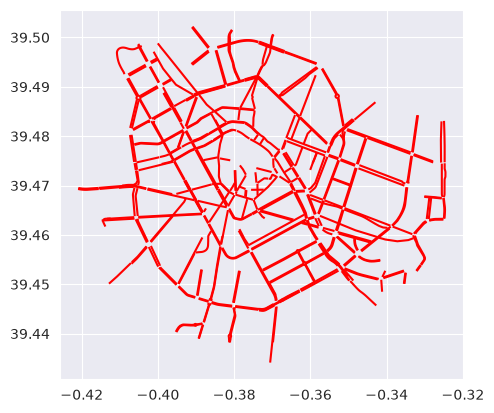

In [26]:
ax = gdf_intensidad_traff.plot(edgecolor="red")

<a id="section6"></a>
<h3><font color="#5E5E5E" size=4>1.5. Análisis de la Contaminación Atmosférica de la Ciudad</font></h3>

In [27]:
gdf_contaminacion_atm =  gpd.read_file("datasets/raw/contaminacion-atmosferica-vlc.xml")
print(gdf_contaminacion_atm.describe())
print(gdf_contaminacion_atm.info())
print(gdf_contaminacion_atm.columns)
gdf_contaminacion_atm.head()

        objectid           utmx          utmy        no2       pm10  \
count  11.000000      11.000000  1.100000e+01  11.000000   9.000000   
mean   17.000000  726288.545455  4.372113e+06  21.727273  26.222222   
std     3.316625    2689.096665  1.177635e+03  11.172206   5.380004   
min    12.000000  722974.000000  4.370204e+06  11.000000  15.000000   
25%    14.500000  723857.000000  4.371117e+06  15.500000  23.000000   
50%    17.000000  725814.000000  4.372060e+06  18.000000  29.000000   
75%    19.500000  728930.000000  4.373175e+06  24.500000  30.000000   
max    22.000000  729839.000000  4.373599e+06  52.000000  32.000000   

            pm25        so2         o3   co  
count   9.000000   6.000000   6.000000  3.0  
mean   11.444444   4.500000  43.166667  0.0  
std     1.878238   6.220932   8.727352  0.0  
min     9.000000   1.000000  30.000000  0.0  
25%    10.000000   1.250000  40.000000  0.0  
50%    11.000000   2.000000  42.000000  0.0  
75%    13.000000   3.500000  48.500000

,gml_id,objectid,Nom___Nombre,Adreça___Direccion,utmx,utmy,Tipus_Zona___Tipo_Zona,tipoemision,Paràmetres___Parámetros,no2,...,pm25,fecha_carga,calidad_ambiental,globalid,fiwareid,Mesuraments___Mediciones,so2,o3,co,geometry
0,Estacions_contaminació_atmosfèriques___Estacio...,12,Dr. Lluch,DR.LLUCH,729839.0,4371969.0,Urbana,Tráfico,"Óxidos de nitrógeno totales (NOx),Monóxido de ...",24.0,...,11.0,2026-06-25T13:00:00,Razonablemente Buena,{72544A7A-34AD-465C-9D05-3646DE5285C6},A08_DR_LLUCH_60m,NaN,NaN,NaN,NaN,POINT (729836.824 4371974.659)
1,Estacions_contaminació_atmosfèriques___Estacio...,13,Francia,AVDA.FRANCIA,728740.0,4371130.0,Urbana,Tráfico,"Dióxido de azufre (SO2),Monóxido de carbono (C...",25.0,...,9.0,2026-06-25T13:00:00,Razonablemente Buena,{A91831BC-DD9A-4957-9C0D-BA60E8DA0602},A01_AVFRANCIA_60m,http://mapas.valencia.es/WebsMunicipales/uploa...,2.0,30.0,0.0,POINT (728601.346 4370954.006)
2,Estacions_contaminació_atmosfèriques___Estacio...,14,Boulevar Sur,BULEVARD SUD,724144.0,4370204.0,Urbana,Tráfico,"Dióxido de azufre (SO2),Ozono,Óxidos de nitróg...",11.0,...,NaN,2026-06-25T13:00:00,Buena,{4074B88B-9F3D-448E-AAB4-D856E94289BD},A02_BULEVARDSUD_60m,http://mapas.valencia.es/WebsMunicipales/uploa...,4.0,44.0,NaN,POINT (724034.376 4369995.131)
3,Estacions_contaminació_atmosfèriques___Estacio...,15,Molí del Sol,MOLÍ DEL SOL,722974.0,4373582.0,Suburbana,Tráfico,"Dióxido de azufre (SO2),Monóxido de carbono (C...",16.0,...,11.0,2026-06-25T13:00:00,Razonablemente Buena,{3DD542DB-13C5-49FD-BA42-536383DC21A6},A03_MOLISOL_60m,http://mapas.valencia.es/WebsMunicipales/uploa...,17.0,55.0,0.0,POINT (722862.964 4373373.741)
4,Estacions_contaminació_atmosfèriques___Estacio...,16,Pista de Silla,PISTA DE SILLA,725814.0,4371104.0,Urbana,Tráfico,"Dióxido de azufre (SO2),Monóxido de carbono (C...",18.0,...,10.0,2026-06-25T13:00:00,Razonablemente Buena,{233DC210-C540-4358-949F-1BFF77C81EB7},A04_PISTASILLA_60m,http://mapas.valencia.es/WebsMunicipales/uploa...,1.0,40.0,0.0,POINT (725704.388 4370895.114)


In [28]:
gdf_contaminacion_atm = gdf_contaminacion_atm[["Nom___Nombre","pm10","pm25","fecha_carga","geometry"]]

gdf_contaminacion_atm = gdf_contaminacion_atm.rename(columns={
    "Nom___Nombre": "station_name",
    "fecha_carga": "measurement_date",
})

gdf_contaminacion_atm["station_id"] = range(1, len(gdf_contaminacion_atm) + 1)
gdf_contaminacion_atm


,station_name,pm10,pm25,measurement_date,geometry,station_id
0,Dr. Lluch,26.0,11.0,2026-06-25T13:00:00,POINT (729836.824 4371974.659),1
1,Francia,29.0,9.0,2026-06-25T13:00:00,POINT (728601.346 4370954.006),2
2,Boulevar Sur,NaN,NaN,2026-06-25T13:00:00,POINT (724034.376 4369995.131),3
3,Molí del Sol,22.0,11.0,2026-06-25T13:00:00,POINT (722862.964 4373373.741),4
4,Pista de Silla,23.0,10.0,2026-06-25T13:00:00,POINT (725704.388 4370895.114),5
5,Universidad Politécnica,15.0,10.0,2026-06-25T13:00:00,POINT (729010.387 4373390.022),6
6,Viveros,NaN,NaN,2026-06-25T13:00:00,POINT (726236.404 4373308.101),7
7,Centro,29.0,11.0,2026-06-25T13:00:00,POINT (725685.212 4372281.788),8
8,Cabanyal,30.0,13.0,2026-06-25T13:00:00,POINT (729790.346 4372829.429),9
9,Olivereta,32.0,15.0,2026-06-25T13:00:00,POINT (723149.199 4372063.529),10


De igual forma que ocurría con el dataset anterior, en este podemos ver que los sensores del ayuntamiento a veces captan las mediciones erróneamente, por lo que, nuevamente tendremos que tener cuidado con los posibles nulls en los datos de calidad ambiental a la hora de montar el pipeline. <br>
Además, para este caso podríamos rellenar los nulls utilizando la última medición registrada o consultando una API externa que nos proporcione información ambiental de la ciudad como podría ser WeatherAPI.

<Axes: xlabel='None', ylabel='% de valores nulos'>

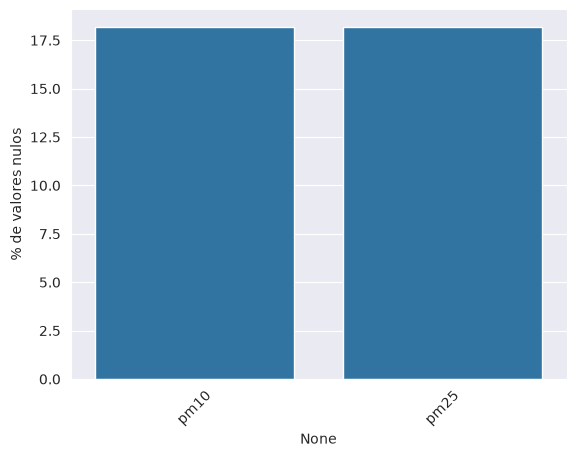

In [29]:
nulls = gdf_contaminacion_atm[["pm10","pm25"]].isna().mean().mul(100).sort_values(ascending=False)

plt.xticks(rotation=45)
plt.ylabel("% de valores nulos")
plt.xlabel("")
sns.barplot(x=nulls.index, y=nulls.values)

In [30]:
gdf_contaminacion_atm = gdf_contaminacion_atm.to_crs("EPSG:4326")
gdf_contaminacion_atm.to_csv(index=False,path_or_buf="datasets/working/contaminacion-ambiental-valencia.csv",sep=";")
gdf_contaminacion_atm.head()

,station_name,pm10,pm25,measurement_date,geometry,station_id
0,Dr. Lluch,26.0,11.0,2026-06-25T13:00:00,POINT (-0.32829 39.46668),1
1,Francia,29.0,9.0,2026-06-25T13:00:00,POINT (-0.34299 39.45783),2
2,Boulevar Sur,NaN,NaN,2026-06-25T13:00:00,POINT (-0.39634 39.4504),3
3,Molí del Sol,22.0,11.0,2026-06-25T13:00:00,POINT (-0.40881 39.48111),4
4,Pista de Silla,23.0,10.0,2026-06-25T13:00:00,POINT (-0.37664 39.45806),5


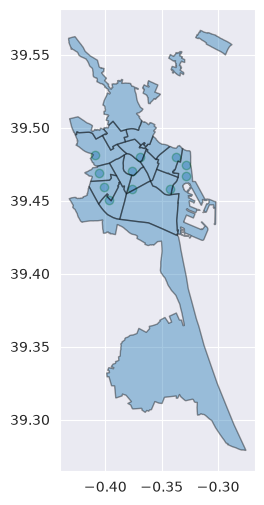

In [31]:
fig, ax = plt.subplots(figsize=(7,6))

gdf_contaminacion_atm.plot(ax=ax,alpha=0.4,edgecolor="green")
gdf_districts.plot(ax=ax,alpha=0.4,edgecolor="black")
plt.show()

<a id="section7"></a>
<h2><font color="#5E5E5E" size=5>2. Análisis Espacial y Transformaciones sobre los Datos</font></h2>

Ahora que hemos analizado y limpiado los datasets que usaremos como base para nuestro proyecto, vamos a realizar sobre ellos las transformaciones y comprobaciones pertinentes para asegurar la calidad y utilidad del deltalake que posteriormente montaremos en base a ellos.

<a id="section8"></a>
<h3><font color="#5E5E5E" size=4>2.1. Análisis Espacial de los Datos</font></h3>

El propósito de este apartado es ver cómo se relacionan los datos especialmente y establecer las relaciones de interés entre ellos. <br> Para nuestro caso de uso, la relación que más nos va a interesar es identificar el distrito y el barrio al que pertenece cada tramo de la ciudad, con el objetivo de calcular métricas de interés en base a la zona de la ciudad en la que nos encontramos. Ya hemos visto en apartados anteriores que la relación distrito-barrio existe, ahora tendremos que hacerla realidad e ir más allá logrando identificar el distrito y barrio asociado a cada tramo en el que se mide la intensidad del tráfico.

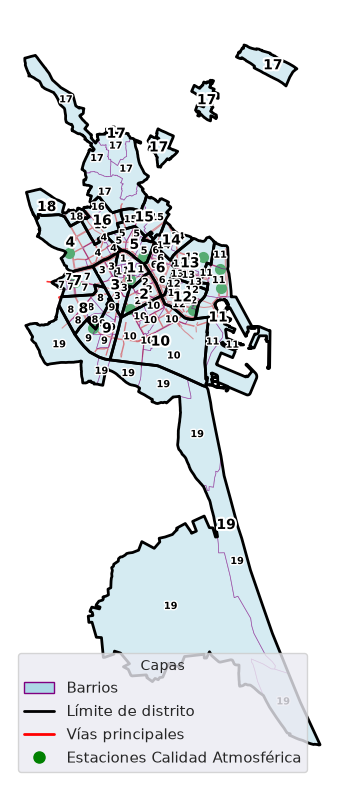

In [32]:
fig, ax = plt.subplots(figsize=(10, 8))

gdf_intensidad_traff.plot(
    ax=ax,
    color="red",
    linewidth=0.8,
    alpha=0.7,
    zorder=1
)

gdf_barrios.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="purple",
    linewidth=0.5,
    alpha=0.5,
    zorder=2
)

gdf_districts.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=2,
    zorder=3
)

gdf_contaminacion_atm.plot(
    ax=ax,
    facecolor="green",
    edgecolor="green",
    linewidth=2,
    zorder=1
)

for _, row in gdf_barrios.iterrows():

    punto = row.geometry.representative_point()

    txt = ax.annotate(
        text=str(row["distrito_id"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=7,
        fontweight="bold",
        color="black",
        zorder=4
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])

for _, row in gdf_districts.iterrows():

    punto = row.geometry.representative_point()

    txt = ax.annotate(
        text=str(row["distrito_id_org"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black",
        zorder=5
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=3, foreground="white")
    ])

legend_elements = [

    Patch(
        facecolor="lightblue",
        edgecolor="purple",
        label="Barrios"
    ),

    Line2D(
        [0], [0],
        color="black",
        lw=2,
        label="Límite de distrito"
    ),

    Line2D(
        [0], [0],
        color="red",
        lw=2,
        label="Vías principales"
    ),

    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="green",
        markeredgecolor="green",
        markersize=8,
        linestyle="None",
        label="Estaciones Calidad Atmosférica"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    fontsize=11,
    title="Capas",
    frameon=True
)


ax.set_axis_off()

plt.tight_layout()

El mapa de la celda anterior representa el estado de los datos que tenemos actualmente, a este mapa habría que sumarle el dataset del callejero de la ciudad que usaremos como base para indicar si una calle esta cortada o no.

<a id="section9"></a>
<h3><font color="#5E5E5E" size=4>2.2. Relación Barrio-Distrito</font></h3>

Ya hemos visto que existe una relación entre los distintos barrios y distritos, es hora de materializarla, pero primero debemos detectar qué barrios pertenecen a los POBLATS DEL NORD e identificar a qué distrito pertenece cada uno, para ello en estos barrios vamos a usar la union espacial que ofrece GeoPandas.

In [33]:
gdf_barrios_pnord = gdf_barrios.query("distrito_id == 17").to_crs(epsg=25830)
gdf_districts_pnord = gdf_districts.query("distrito_id_org == 17").to_crs(epsg=25830)

gdf_barr_distr_pnord = gpd.sjoin_nearest(
    gdf_districts_pnord,
    gdf_barrios_pnord,
    how="left"
)[["barrio_id","nombre_barrio","distrito_id_left", "nombre_distrito", "geometry", "distrito_id_org"]]

gdf_barr_distr_pnord.rename(columns={"distrito_id_left":"distrito_id"}, inplace=True)

gdf_barr_distr_pnord_grp = (
    gdf_barr_distr_pnord
    .groupby(["distrito_id", "geometry"], as_index=False)
    .agg(
        nombre_barrios=("nombre_barrio", lambda x: ", ".join(x.unique()))
    )
    .pipe(gpd.GeoDataFrame, geometry="geometry", crs=gdf_districts_pnord.crs)
)


Text(0.5, 1.0, 'Distritos con Barrios Asociados')

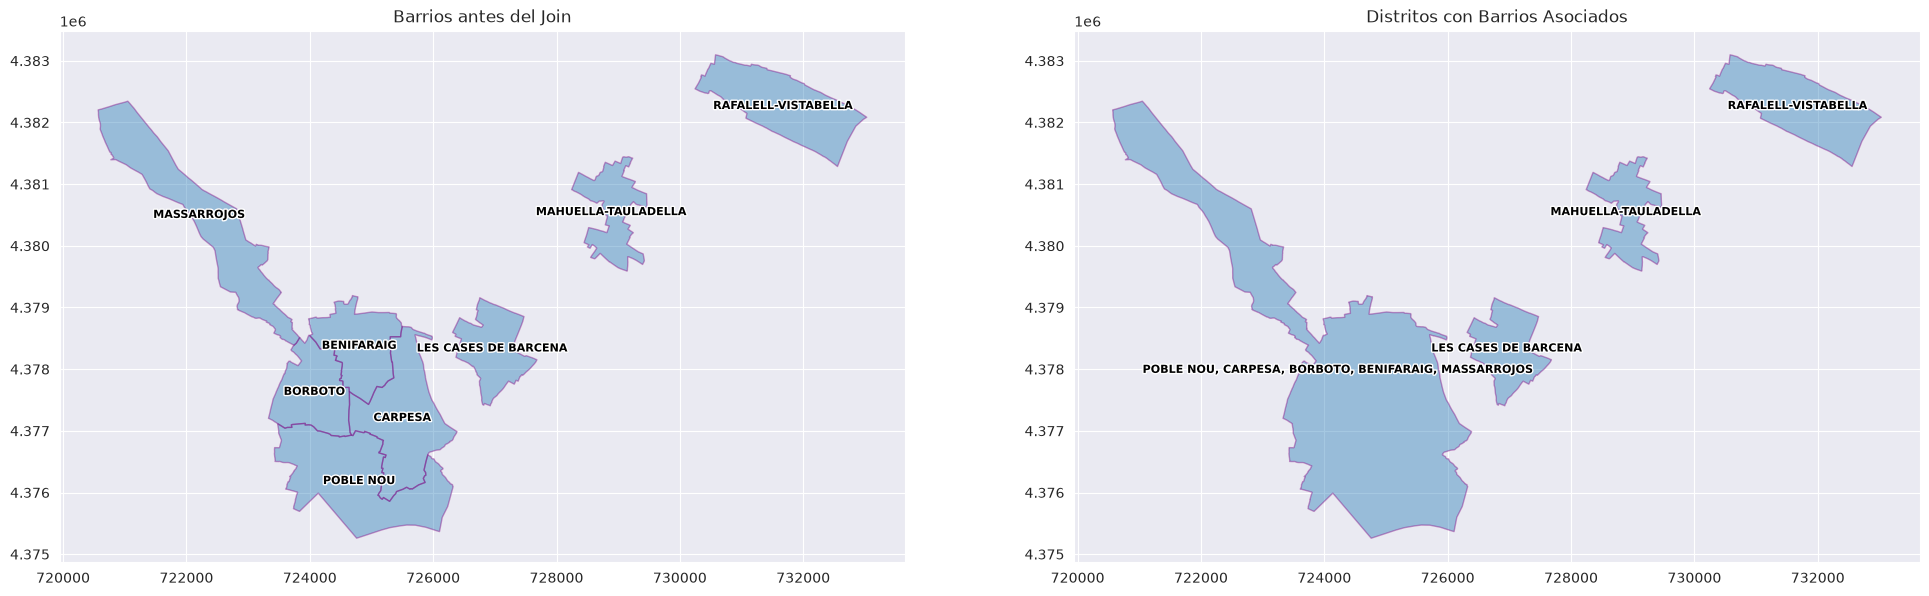

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(24, 20))

gdf_barrios_pnord.plot(ax=axes[0], alpha=0.4, edgecolor="purple")

for _, row in gdf_barrios_pnord.iterrows():
    punto = row.geometry.centroid

    txt = axes[0].annotate(
        text=str(row["nombre_barrio"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=8,
        color="black",
        fontweight="bold"
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])

gdf_barr_distr_pnord_grp.plot(ax=axes[1], alpha=0.4, edgecolor="purple")


for _, row in gdf_barr_distr_pnord_grp.iterrows():
    punto = row.geometry.centroid

    txt = axes[1].annotate(
        text=str(row["nombre_barrios"]),
        xy=(punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=8,
        color="black",
        fontweight="bold"
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])

axes[0].set_title("Barrios antes del Join")
axes[1].set_title("Distritos con Barrios Asociados")


Con el mapa anterior podemos confirmar que la relación para los barrios del nord ha sido exitosa, ahora vamos a relacionar el resto de barrios con sus respectivos distritos.

In [35]:

gdf_barrios_pnord_cleaned = gdf_barr_distr_pnord[["barrio_id","nombre_barrio","distrito_id","distrito_id_org"]].merge(gdf_barrios[["barrio_id","geometry"]], how="inner", on="barrio_id")
gdf_barrios_without_pn = gdf_barrios.query("distrito_id != 17").merge(
    gdf_districts[["distrito_id_org","distrito_id"]],
    how="inner",
    left_on="distrito_id", right_on="distrito_id_org"
).rename(columns={"distrito_id_y":"distrito_id"}).drop(columns="distrito_id_x")
gdf_barrios_cleaned = pd.concat([gdf_barrios_without_pn,gdf_barrios_pnord_cleaned])
gdf_barrios_cleaned.to_csv(index=False,path_or_buf="datasets/working/barrios-with-distrito.csv", sep=";")
gdf_barrios_cleaned


,barrio_id,nombre_barrio,geometry,distrito_id_org,distrito_id
0,0,LA CREU COBERTA,"POLYGON ((-0.38124 39.45463, -0.38281 39.44951...",9,9
1,1,LA FONTETA S.LLUIS,"POLYGON ((-0.36941 39.44772, -0.36826 39.44819...",10,10
2,3,CAMI DE VERA,"POLYGON ((-0.35156 39.48155, -0.35442 39.48244...",14,14
3,4,BENIMAMET,"POLYGON ((-0.42651 39.495, -0.42653 39.49506, ...",18,21
4,5,BENIFERRI,"POLYGON ((-0.41244 39.49773, -0.41243 39.49772...",18,21
...,...,...,...,...,...
3,75,POBLE NOU,"POLYGON ((-0.40036 39.51462, -0.39903 39.51394...",17,20
4,10,CARPESA,"POLYGON ((-0.3672 39.51203, -0.36734 39.51182,...",17,20
5,11,BORBOTO,"POLYGON ((-0.38788 39.52056, -0.38788 39.51965...",17,20
6,12,BENIFARAIG,"POLYGON ((-0.37639 39.52831, -0.37667 39.52737...",17,20


,barrio_id,nombre_barrio,geometry,distrito_id_org,distrito_id
0,2,RAFALELL-VISTABELLA,"POLYGON ((-0.28767 39.55682, -0.28829 39.55654...",17,17
1,77,MAHUELLA-TAULADELLA,"POLYGON ((-0.32961 39.54649, -0.3296 39.54609,...",17,18
2,76,LES CASES DE BARCENA,"POLYGON ((-0.3554 39.52535, -0.35582 39.52461,...",17,19
3,75,POBLE NOU,"POLYGON ((-0.40036 39.51462, -0.39903 39.51394...",17,20
5,11,BORBOTO,"POLYGON ((-0.38788 39.52056, -0.38788 39.51965...",17,20
4,10,CARPESA,"POLYGON ((-0.3672 39.51203, -0.36734 39.51182,...",17,20
7,79,MASSARROJOS,"POLYGON ((-0.41713 39.55177, -0.41679 39.55153...",17,20
6,12,BENIFARAIG,"POLYGON ((-0.37639 39.52831, -0.37667 39.52737...",17,20
3,4,BENIMAMET,"POLYGON ((-0.42651 39.495, -0.42653 39.49506, ...",18,21
4,5,BENIFERRI,"POLYGON ((-0.41244 39.49773, -0.41243 39.49772...",18,21


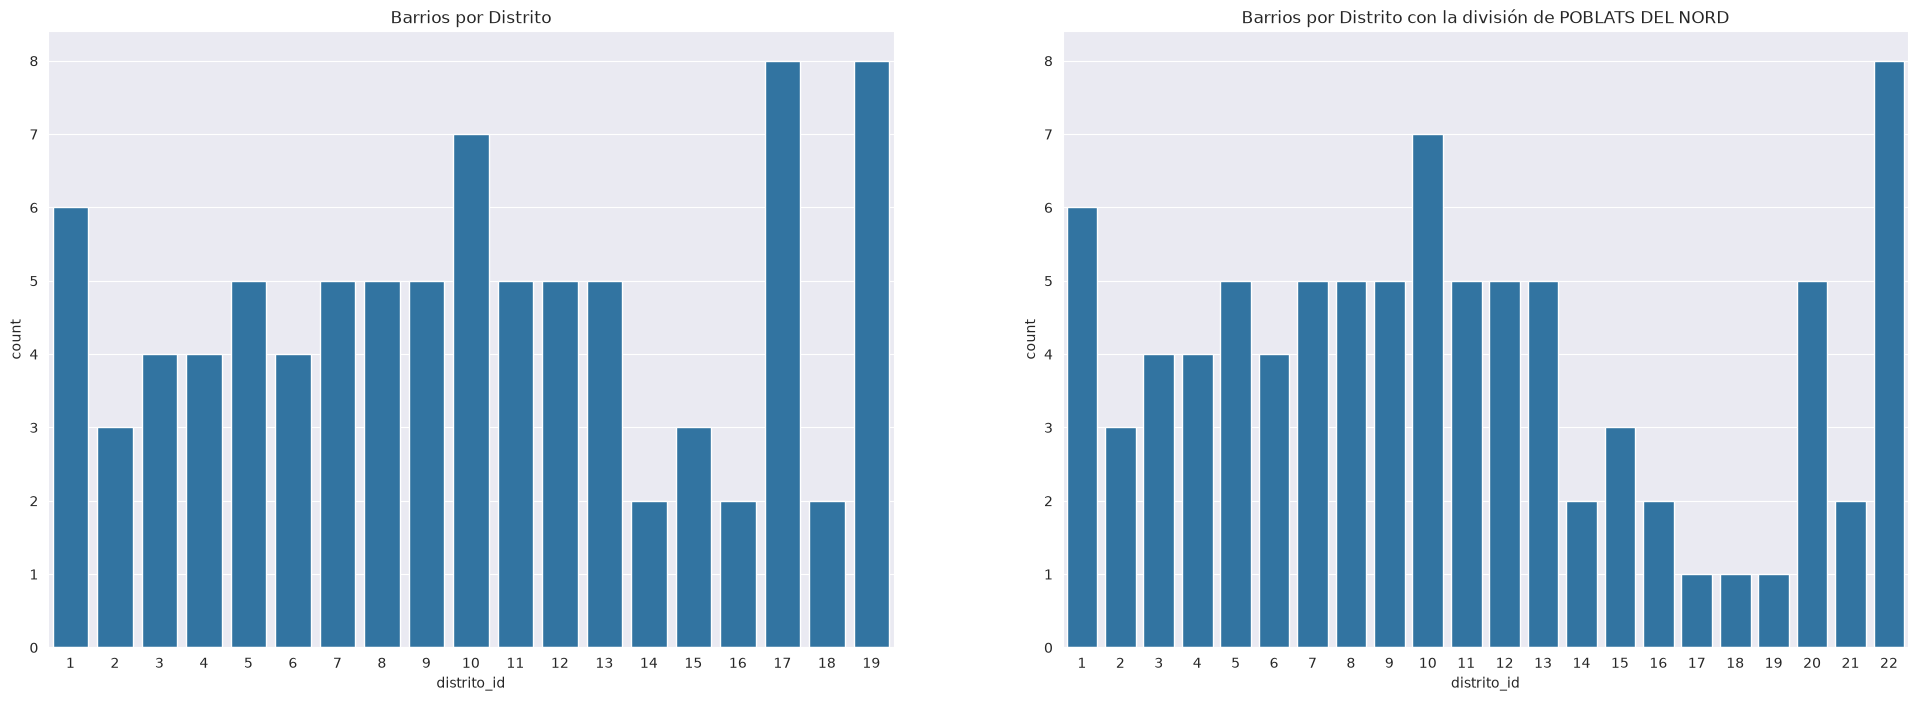

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(24, 8))

sns.countplot(ax=axes[0], data=gdf_barrios.sort_values(by="distrito_id", ascending=True), x="distrito_id")
sns.countplot(ax=axes[1], data=gdf_barrios_cleaned.sort_values(by="distrito_id", ascending=True), x="distrito_id")

axes[0].set_title("Barrios por Distrito")
axes[1].set_title("Barrios por Distrito con la división de POBLATS DEL NORD")

gdf_barrios_cleaned.query("distrito_id > 16").sort_values(by="distrito_id")

En el gráfico superior podemos ver como la distribución de barrios por distrito se mantiene igual con la diferencia de que al separar los POBLATS DEL NORD en los distritos con IDs 17,18,19 y 20, la distribución de barrios para estos ha cambiado. Además, fruto de la generación de un nuevo ID, el distrito con ID=18 ha pasado a ser el ID=21 y lo mismo ha ocurrido para el distrito con ID=19 que ha pasado a ser el 22.

<a id="section10"></a>
<h3><font color="#5E5E5E" size=4>2.3. Relación Tramo-Barrio-Distrito</font></h3>

El siguiente paso es identificar en qué barrio y distrito se encuentra cada uno de los tramos en los que se mide la intensidad del tráfico. Para ello nos vamos a ayudar de nuevo de la unión espacial de GeoPandas.

<Axes: >

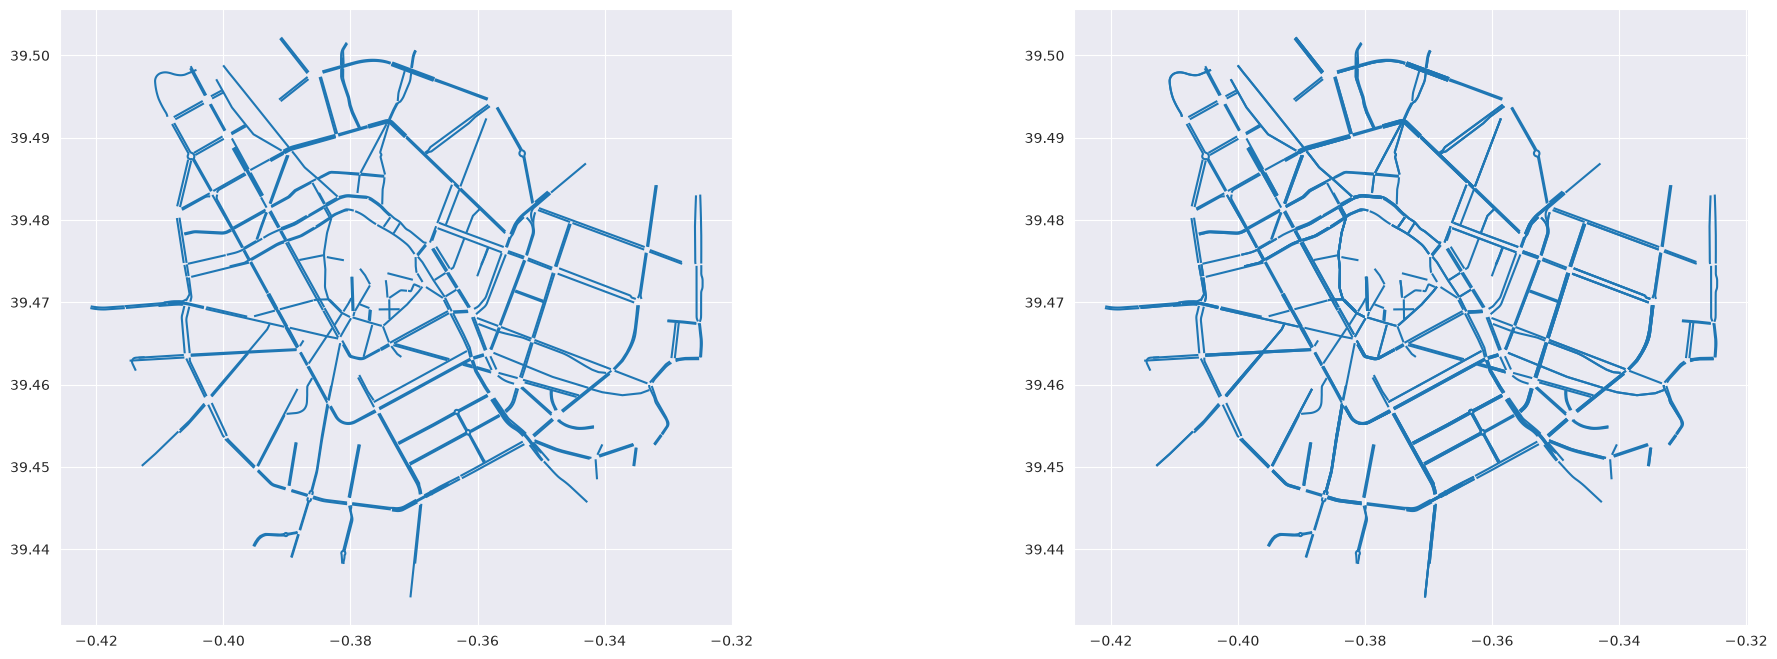

In [37]:
gdf_intensidad_traff_barrio = gpd.sjoin(
    gdf_intensidad_traff,
    gdf_barrios[["barrio_id","nombre_barrio","distrito_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

fig, axes = plt.subplots(1, 2, figsize=(24, 8))

gdf_intensidad_traff.plot(ax=axes[0])
gdf_intensidad_traff_barrio.plot(ax=axes[1])

In [38]:
print("##########################")
print("Antes del Join Espacial")
print("########################")
gdf_intensidad_traff.describe()
gdf_intensidad_traff.info()
print("##########################")
print("Después del Join Espacial")
print("##########################")
gdf_intensidad_traff_barrio.describe()
gdf_intensidad_traff_barrio.info()

##########################
Antes del Join Espacial
########################
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 411 entries, 0 to 445
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   tramo_id      411 non-null    int64   
 1   nombre_tramo  411 non-null    str     
 2   estado        411 non-null    float64 
 3   geometry      411 non-null    geometry
dtypes: float64(1), geometry(1), int64(1), str(1)
memory usage: 33.3 KB
##########################
Después del Join Espacial
##########################
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 638 entries, 0 to 445
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   tramo_id       638 non-null    int64   
 1   nombre_tramo   638 non-null    str     
 2   estado         638 non-null    float64 
 3   geometry       638 non-null    geometry
 4   index_right    638 

Como podemos ver, tras el join espacial tenemos muchas más filas que antes, sin embargo, al observar el mapa de las vías no hemos perdido ninguna de ellas. Esto posiblemente se debe a que hay tramos que pasan por más de un barrio, ante esta situación, lo que vamos a hacer es separar cada una de las partes del tramo con su barrio correspondiente.

In [39]:
print(gdf_intensidad_traff[["nombre_tramo"]].value_counts())
print(gdf_intensidad_traff_barrio[["nombre_tramo"]].value_counts())


nombre_tramo                                          
HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR)       2
HNOS. MACHADO (DE ALFAHUIR A JUAN XXIII)                  2
MARIA CRISTINA                                            1
JOAQUIN BALLESTER HACIA PÍO XII                           1
CNO. NUEVO DE PICAÑA HACIA CV-36                          1
                                                         ..
CARTEROS HACIA CENTRO CIUDAD                              1
CAMPANAR (DE TIRSO DE MOLINA A PÍO XII)                   1
PASO INFERIOR TIRSO DE MOLINA - MANUEL DE FALLA           1
GERMANIES CAP A PAS INFERIOR                              1
CONSTITUCIÓN (DE HERMANOS MACHADO A TAVERNES BLANQUES)    1
Name: count, Length: 409, dtype: int64
nombre_tramo                                                               
GUILLEM DE CASTRO                                                              5
HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR)                            4
PASO INF

Aquí podemos ver que el tramo que más se ha duplicado es GUILLEM DE CASTRO por lo que centraremos el análisis en este tramo. Además, vemos que el dataset original también aparece el tramo HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR) repetido dos veces, por lo que, este también merece especial atención por si fuera un error del Ayuntamiento.

     tramo_id       nombre_tramo  estado  \
390      1913  GUILLEM DE CASTRO     0.0   
390      1913  GUILLEM DE CASTRO     0.0   
390      1913  GUILLEM DE CASTRO     0.0   
390      1913  GUILLEM DE CASTRO     0.0   
390      1913  GUILLEM DE CASTRO     0.0   

                                              geometry  index_right  \
390  MULTILINESTRING ((-0.38007 39.46821, -0.38118 ...           28   
390  MULTILINESTRING ((-0.38007 39.46821, -0.38118 ...           20   
390  MULTILINESTRING ((-0.38007 39.46821, -0.38118 ...           84   
390  MULTILINESTRING ((-0.38007 39.46821, -0.38118 ...           24   
390  MULTILINESTRING ((-0.38007 39.46821, -0.38118 ...           19   

     barrio_id  nombre_barrio  distrito_id  
390         28     LA ROQUETA            3  
390         20     EL BOTANIC            3  
390         84  SANT FRANCESC            1  
390         24       EL PILAR            1  
390         19       EL CARME            1  


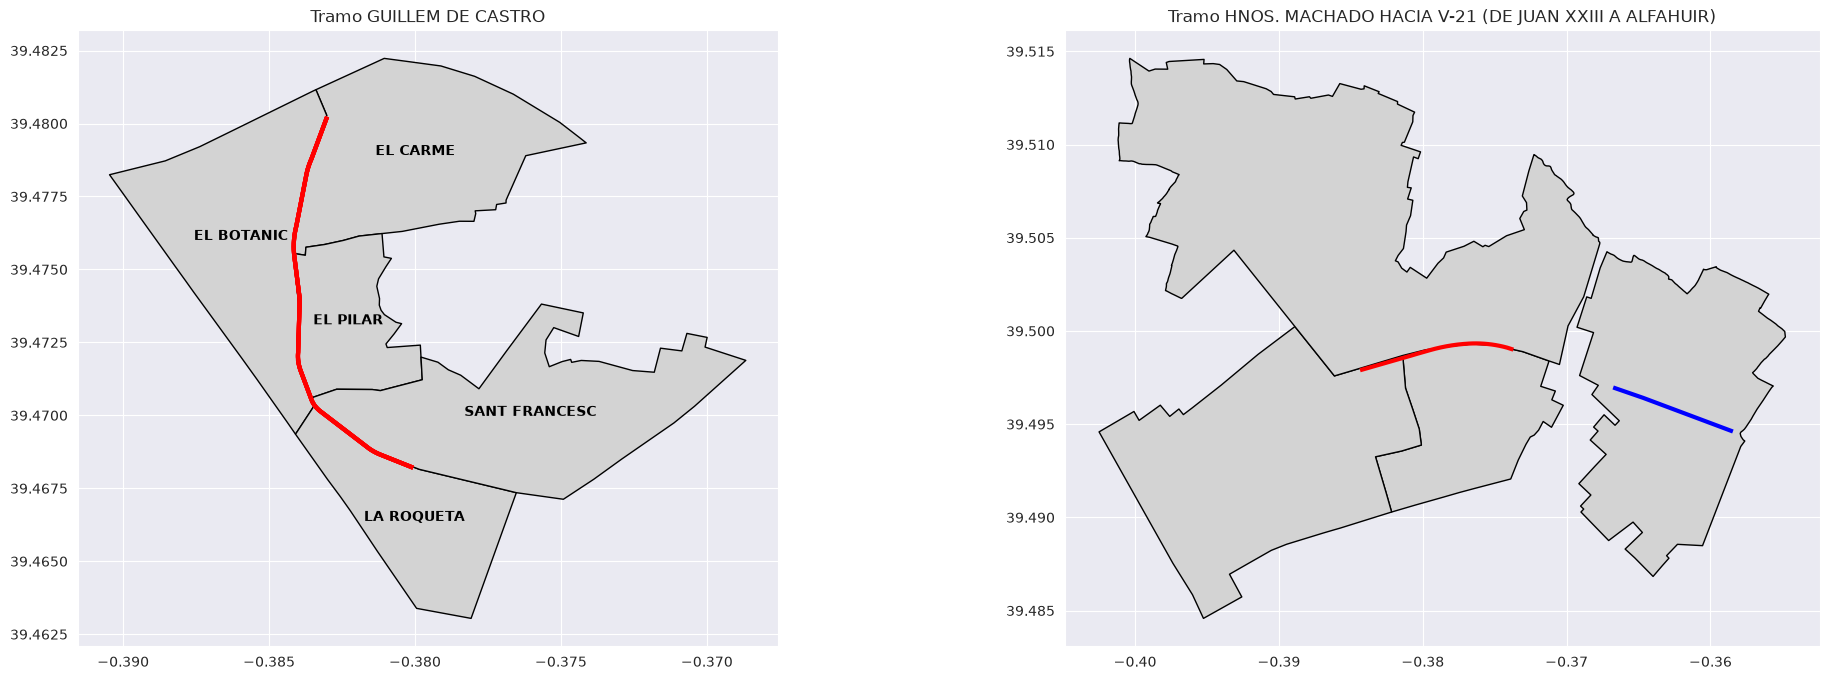

In [40]:
tramo_mas_repetido = gdf_intensidad_traff_barrio.loc[gdf_intensidad_traff_barrio["nombre_tramo"] == "GUILLEM DE CASTRO"]
barrios_tramo = gdf_barrios[gdf_barrios["nombre_barrio"].isin(tramo_mas_repetido["nombre_barrio"].to_list())]
print(tramo_mas_repetido)

tramo_hmnos_machado = gdf_intensidad_traff[gdf_intensidad_traff["nombre_tramo"] == "HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR)"].set_crs(gdf_barrios.crs)
barrios_tramo_hmnos_machado = gdf_barrios[gdf_barrios["nombre_barrio"].isin(gdf_intensidad_traff_barrio.query("nombre_tramo == 'HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR)'")["nombre_barrio"].to_list())]


fig, axes = plt.subplots(1, 2, figsize=(24, 8))

barrios_tramo.plot(
    ax=axes[0],
    facecolor="lightgrey",
    edgecolor="black"
)

for _, row in barrios_tramo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y

    axes[0].text(
        x,
        y,
        row["nombre_barrio"],
        fontsize=10,
        fontweight="bold",
        color="black",
        ha="center",
        va="center"
    )

for i, (_, row) in enumerate(tramo_mas_repetido.iterrows()):
    gpd.GeoSeries([row.geometry]).plot(
        ax=axes[0],
        color="red",
        linewidth=3
    )

barrios_tramo_hmnos_machado.plot(
    ax=axes[1],
    facecolor="lightgrey",
    edgecolor="black"
)

tramo_hmnos_machado.iloc[[0]].plot(ax=axes[1],color="red",linewidth=3)
tramo_hmnos_machado.iloc[[1]].plot(ax=axes[1],color="blue",linewidth=3)

axes[0].set_title("Tramo GUILLEM DE CASTRO")
axes[1].set_title("Tramo HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR)")

plt.show()


Como habíamos predecido, este tramo cruza varios barrios, y este es el motivo de que se dupliquen las filas. Para solucionarlo en lugar de un join espacial, vamos a utilizar un Overlay.<br>
Por otro lado, podemos ver que el tramo HNOS. MACHADO HACIA V-21 (DE JUAN XXIII A ALFAHUIR) ha sido divido en dos partes por el ayuntamiento y es por ello por lo que aparece repetido, por lo que esto no debería preocuparnos.

In [41]:
gdf_tramos_barrios = gpd.overlay(
    gdf_intensidad_traff,
    gdf_barrios[["barrio_id", "nombre_barrio", "distrito_id", "geometry"]],
    how="intersection",
    keep_geom_type=True
)

gdf_tramos_barrios.to_csv(index=False,path_or_buf="datasets/working/tramos-with-barrio-distrito.csv",sep=";")


<Axes: >

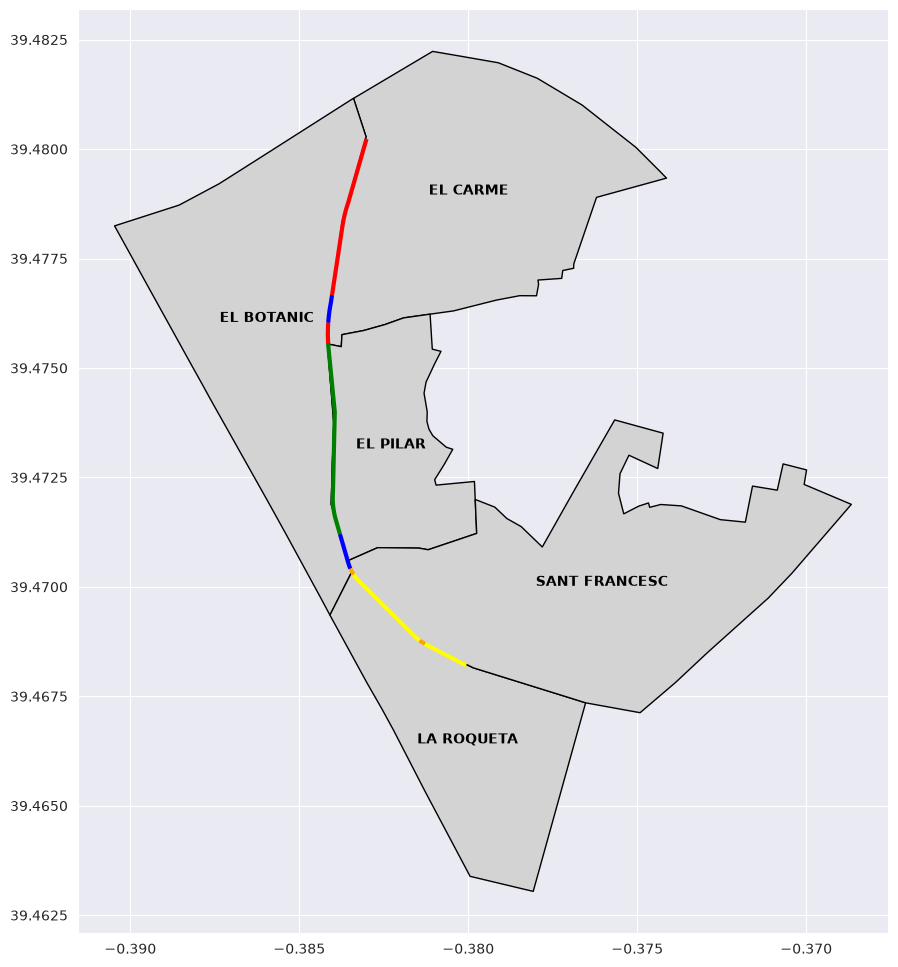

In [42]:
tramo_mas_repetido = gdf_tramos_barrios.loc[gdf_tramos_barrios["nombre_tramo"] == "GUILLEM DE CASTRO"]
barrios_tramo = gdf_barrios[gdf_barrios["nombre_barrio"].isin(tramo_mas_repetido["nombre_barrio"].to_list())]

fig, ax = plt.subplots(figsize=(14,12))

barrios_tramo.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="black"
)

for _, row in barrios_tramo.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y

    ax.text(
        x,
        y,
        row["nombre_barrio"],
        fontsize=10,
        fontweight="bold",
        color="black",
        ha="center",
        va="center"
    )

tramo_mas_repetido.iloc[[0]].plot(ax=ax,color="red",linewidth=3)
tramo_mas_repetido.iloc[[1]].plot(ax=ax,color="blue",linewidth=3)
tramo_mas_repetido.iloc[[2]].plot(ax=ax,color="green",linewidth=3)
tramo_mas_repetido.iloc[[3]].plot(ax=ax,color="yellow",linewidth=3)
tramo_mas_repetido.iloc[[4]].plot(ax=ax,color="orange",linewidth=3)

<a id="section11"></a>
<h3><font color="#5E5E5E" size=4>2.4. Relación Tramo-Estación Ambiental</font></h3>

Finalmente, vamos a asociar cada uno de los tramos en los que vamos a analizar el tráfico con la estación ambiental más cercana.

In [43]:
gdf_tramo_barrio_contaminacion = gpd.sjoin_nearest(
    gdf_tramos_barrios.to_crs(25830),
    gdf_contaminacion_atm.to_crs(25830),
    how="inner"
)
print(gdf_tramo_barrio_contaminacion["station_id"].value_counts())
gdf_tramo_barrio_contaminacion = gdf_tramo_barrio_contaminacion[["tramo_id","nombre_tramo","barrio_id","nombre_barrio","distrito_id","station_name","station_id"]]
gdf_tramo_barrio_contaminacion.to_csv(index=False,path_or_buf="datasets/working/tramos-distrito-barrio-station.csv",sep=";")
gdf_tramo_barrio_contaminacion


station_id
7     162
8      88
2      88
5      78
4      68
10     45
6      34
3      29
1      19
11     18
9       9
Name: count, dtype: int64


,tramo_id,nombre_tramo,barrio_id,nombre_barrio,distrito_id,station_name,station_id
0,1862,MARIA CRISTINA,23,EL MERCAT,1,Centro,8
1,2217,JOAQUIN BALLESTER HACIA PÍO XII,64,CAMPANAR,4,Molí del Sol,4
2,2217,JOAQUIN BALLESTER HACIA PÍO XII,65,LES TENDETES,4,Viveros,7
3,2110,CNO. NUEVO DE PICAÑA HACIA CV-36,56,VARA DE QUART,8,Patraix,11
4,1995,CUENCA (DE PÉREZ GALDÓS A ALBERIQUE),27,ARRANCAPINS,3,Centro,8
...,...,...,...,...,...,...,...
633,2108,PASO INFERIOR TIRSO DE MOLINA - MANUEL DE FALLA,62,SANT PAU,4,Olivereta,10
634,2108,PASO INFERIOR TIRSO DE MOLINA - MANUEL DE FALLA,64,CAMPANAR,4,Olivereta,10
635,1926,GERMANIES CAP A PAS INFERIOR,52,RUSSAFA,2,Centro,8
636,2018,CONSTITUCIÓN (DE HERMANOS MACHADO A TAVERNES B...,75,POBLE NOU,17,Viveros,7


<a id="section12"></a>
<h3><font color="#5E5E5E" size=4>2.5. Conclusiones y Consolidación de Datasets</font></h3>

Las conclusiones resultantes de este análisis exploratorio de datos son las siguientes:<br>
- El callejero de Valencia ofrecido por el ayuntamiento es muy pobre, por lo que, usaremos uno propio generado gracias a OpenStreetMap con el propósito de indicar en qué tramos de la ciudad el paso está cortado.
- Existe una relación clara entre distritos y barrios los cual nos va a permitir calcular estadísticas por zona, y hemos tenido que hacer varias transformaciones debido a que el distrito POBLATS DEL NORD se divide en 4 zonas distintas de la ciudad.
- Los datasets que proporcionan lo que será el corazón de nuestro proyecto son la intensidad del tráfico en los distintos puntos de la ciudad y la calidad atmosférica no necesitan a penas modificaciones, pero si que será necesario controlar las posibles mediciones erróneas por parte del ayuntamiento las cuales se traducen en valores nulos.
- Finalmente, debemos establecer la relación entre los distintos tramos con su estación de calidad atmosférica más cercana, barrio y distrito para poder calcular las métricas correctamente.

Para concluir con el análisis vamos a consolidar los datasets que utilizaremos como base para poder calcular las métricas por zona de la ciudad en tiempo de ejecución de los distintos pipelines.

In [44]:
gdf_barrios_distritos = gdf_barrios_cleaned.merge(
    gdf_districts[["distrito_id","nombre_distrito","geometry"]].rename(columns={"geometry": "geometry_distrito"}),
    how="inner",
    on="distrito_id"
).rename(columns={"geometry": "geometry_barrio"}).sort_values(by="distrito_id")

gdf_barrios_distritos[["barrio_id","nombre_barrio","geometry_barrio","distrito_id","nombre_distrito","geometry_distrito"]].to_csv(index=False,path_or_buf="datasets/consolidated/barrios-con-distrito.csv",sep=";")

pd.read_csv("datasets/consolidated/barrios-con-distrito.csv",sep=";").head()


,barrio_id,nombre_barrio,geometry_barrio,distrito_id,nombre_distrito,geometry_distrito
0,19,EL CARME,POLYGON ((-0.3810545927106667 39.4822317440009...,1,CIUTAT VELLA,POLYGON ((-0.3810545927151668 39.4822317430748...
1,24,EL PILAR,POLYGON ((-0.3811295209731552 39.4762291083116...,1,CIUTAT VELLA,POLYGON ((-0.3810545927151668 39.4822317430748...
2,22,LA XEREA,POLYGON ((-0.3705870978338092 39.4772071916823...,1,CIUTAT VELLA,POLYGON ((-0.3810545927151668 39.4822317430748...
3,23,EL MERCAT,POLYGON ((-0.379170386646021 39.47654978724182...,1,CIUTAT VELLA,POLYGON ((-0.3810545927151668 39.4822317430748...
4,87,LA SEU,POLYGON ((-0.3705870978338092 39.4772071916823...,1,CIUTAT VELLA,POLYGON ((-0.3810545927151668 39.4822317430748...


In [45]:
df_working_estaciones_atm = pd.read_csv("datasets/working/contaminacion-ambiental-valencia.csv",sep=";")
df_working_estaciones_atm = df_working_estaciones_atm[["station_id","station_name","geometry"]].rename(columns={"geometry":"geometry_station"})

df_working_estaciones_atm.to_csv(index=False,path_or_buf="datasets/consolidated/estaciones-calidad-ambiental.csv",sep=";")

pd.read_csv("datasets/consolidated/estaciones-calidad-ambiental.csv",sep=";").head()

,station_id,station_name,geometry_station
0,1,Dr. Lluch,POINT (-0.328289489397558 39.466684756387046)
1,2,Francia,POINT (-0.3429862324176645 39.45782688844423)
2,3,Boulevar Sur,POINT (-0.3963375643715274 39.45039600643123)
3,4,Molí del Sol,POINT (-0.4088098968967599 39.48111211183018)
4,5,Pista de Silla,POINT (-0.3766439365745978 39.458060954622646)


In [46]:
df_working_tramos = pd.read_csv("datasets/working/tramos-with-barrio-distrito.csv",sep=";")
df_tramos_mapping = df_working_tramos.merge(gdf_tramo_barrio_contaminacion, how="inner", on=["tramo_id","barrio_id","distrito_id","nombre_tramo"])
df_tramos_mapping = df_tramos_mapping[["tramo_id","nombre_tramo","geometry","barrio_id","distrito_id","station_id"]].rename(columns={"geometry":"geometry_tramo"})
df_tramos_mapping["tramo_id"] = df_tramos_mapping["tramo_id"].astype("Int64")

df_tramos_mapping.to_csv(index=False,path_or_buf="datasets/consolidated/tramos-con-mappings.csv",sep=";")

pd.read_csv("datasets/consolidated/tramos-con-mappings.csv",sep=";").head()

,tramo_id,nombre_tramo,geometry_tramo,barrio_id,distrito_id,station_id
0,1862,MARIA CRISTINA,LINESTRING (-0.3769222698243007 39.47219342763...,23,1,8
1,2217,JOAQUIN BALLESTER HACIA PÍO XII,LINESTRING (-0.3880029202682664 39.48392450547...,64,4,4
2,2217,JOAQUIN BALLESTER HACIA PÍO XII,LINESTRING (-0.3854102833723691 39.48496608246...,65,4,7
3,2110,CNO. NUEVO DE PICAÑA HACIA CV-36,LINESTRING (-0.4030119585898885 39.45769604328...,56,8,11
4,1995,CUENCA (DE PÉREZ GALDÓS A ALBERIQUE),LINESTRING (-0.3879477499156185 39.46468221682...,27,3,8


In [47]:

gdf_barrios_distritos = gdf_barrios_distritos.set_geometry("geometry_barrio")
gdf_callejero_mappings = gpd.sjoin_nearest(
    gdf_callejero_cleaned[["tramo_osm_id","nombre_tramo", "geometry"]],
    gdf_barrios_distritos[["barrio_id","nombre_barrio","geometry_barrio","distrito_id","nombre_distrito"]],
    how='inner'
).drop(columns=["index_right"]).rename(columns={"geometry":"geometry_tramo"})

gdf_callejero_mappings.to_csv(index=False,path_or_buf="datasets/consolidated/callejero-con-mappings.csv",sep=";")

pd.read_csv("datasets/consolidated/callejero-con-mappings.csv",sep=";").head()

/home/manu/tfm-smart-mobility-vlc/.venv/lib/python3.14/site-packages/geopandas/array.py:411: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


,tramo_osm_id,nombre_tramo,geometry_tramo,barrio_id,nombre_barrio,distrito_id,nombre_distrito
0,0,"[""Carrer de Xàtiva""]","LINESTRING (-0.3750385 39.4671301, -0.3751932 ...",52,RUSSAFA,2,L'EIXAMPLE
1,0,"[""Carrer de Xàtiva""]","LINESTRING (-0.3750385 39.4671301, -0.3751932 ...",84,SANT FRANCESC,1,CIUTAT VELLA
2,1,"[""Plaça de l'Ajuntament""]","LINESTRING (-0.3768172 39.4692273, -0.3766547 ...",84,SANT FRANCESC,1,CIUTAT VELLA
3,2,"[""Avinguda del Marqués de Sotelo""]","LINESTRING (-0.3768172 39.4692273, -0.3768673 ...",84,SANT FRANCESC,1,CIUTAT VELLA
4,3,"[""Plaça de l'Ajuntament"", ""Carrer del Periodis...","LINESTRING (-0.3786529 39.4697863, -0.3785713 ...",84,SANT FRANCESC,1,CIUTAT VELLA


<a id="section13"></a>
<h3><font color="#5E5E5E" size=4>BONUS. Análisis de Grafos para el Cálculo de Rutas</font></h3>

Cuando se realizó este EDA al inicio del proyecto no se tuvo en cuenta que estamos usando dos fuentes distintas para formar el mapa de la ciudad.
Por un lado, tenemos los datos espaciales proporcionados por el ayuntamiento de la ciudad y que hemos usado para calcular tráfico y la contaminación en los distintos puntos de la ciudad, y por otro lado el proporcionado por OpenStreetMap que sabemos que sí es un gráfico válido.
Es por ello que vamos a ver si es posible transformar los datos del ayuntamiento en un grafo, puesto que, así seríamos fieles a la ubicación espacial donde se producen los datos y en caso de no ser posible, realizaríamos las transformaciones pertinentes para poder establecer un mapping entre las ubicaciones de los datos procedentes del ayuntamiento y los de OpenStreetMap, siendo estos últimos los que usaríamos para calcular las rutas.

In [48]:
# Generar grafo con los datos del ayuntamiento:

gdf_vlc = gdf_tramos_barrios.copy()

gdf_vlc = gdf_vlc.explode(index_parts=False).reset_index(drop=True)

gdf_vlc["start"] = gdf_vlc.geometry.apply(lambda g: tuple(g.coords[0]))
gdf_vlc["end"] = gdf_vlc.geometry.apply(lambda g: tuple(g.coords[-1]))

G = nx.Graph()

for _, row in gdf_vlc.iterrows():

    G.add_edge(
        row["start"],
        row["end"],
        tramo_id=row["tramo_id"],
        station_id=row.get("station_id", None),
        geometry=row["geometry"],
        length=row["geometry"].length
    )

print(f"Nodos: {G.number_of_nodes()}")
print(f"Aristas: {G.number_of_edges()}")
print(f"Componentes conexas: {nx.number_connected_components(G)}")

Nodos: 1076
Aristas: 660
Componentes conexas: 416


In [49]:

G = nx.Graph()

for _, row in gdf_callejero_cleaned.iterrows():

    G.add_edge(
        row["u"],
        row["v"],
        key=row["key"],
        length=row["length"],
        geometry=row["geometry"]
    )

print(f"Nodos: {G.number_of_nodes()}")
print(f"Aristas: {G.number_of_edges()}")
print(f"Componentes conexas: {nx.number_connected_components(G)}")

Nodos: 8091
Aristas: 12322
Componentes conexas: 1


Aunque se ve visualmente si comparamos el mapa de ambos GeoDataFrames, ahora hemos demostrado de una forma más objetivo y empírica que para el cáclulo de rutas va a ser más conveniente realizarlo con los datos de OpenStreetMap, ya que, estos forman un grafo perfectamente conectado sin ningún dead-node o arista faltante.

In [50]:
# Establecer relación entre calles de OpenStreetMap y el Ayuntamiento de Valencia para poder calcular las rutas:
mapping_entre_tramos = gpd.sjoin(
    gdf_intensidad_traff[["tramo_id", "nombre_tramo", "geometry"]],
    gdf_callejero_cleaned[["tramo_osm_id", "osmid", "u", "v", "key", "length", "geometry"]],
    predicate="intersects",
    how="inner"
)

# Un tramo se puede asociar a varios tramos de OSM, pero no puede ocurrir al revés ya que podría darse el caso de que asignaramos a un mismo tramo de OSM dos 
# salidas del FIS distintas
conflictos = (
    mapping_entre_tramos.groupby(["u","v","key"])["tramo_id"]
    .nunique()
)

# Nos quedamos con los tramos conflictivos
conflictos = conflictos[conflictos > 1]

conflictos.value_counts()

tramo_id
2    134
3      9
4      4
Name: count, dtype: int64

In [51]:
# Ahora lo que vamos a hacer es calcular qué tramo tiene mayor solapamiento con el tramo de OSM y este será al que le daremos prioridad para el mapping

# Recuperamos el tramo original de OSM
mapping_entre_tramos = mapping_entre_tramos.merge(
    gdf_callejero_cleaned[
        ["tramo_osm_id", "geometry"]
    ].rename(columns={"geometry": "geometry_osm"}),
    on="tramo_osm_id",
    how="left"
)
# Calculamos el área de solape
mapping_entre_tramos["overlap"] = (
    mapping_entre_tramos.apply(lambda row: row.geometry.intersection(row.geometry_osm).length,axis=1)
)
# Calculamos el % de solape
mapping_entre_tramos["coverage"] = (
    mapping_entre_tramos["overlap"] / mapping_entre_tramos["length"]
)
# Ordenamos de mayor a menor cobertura
mapping_final = (
    mapping_entre_tramos
    .sort_values("coverage", ascending=False)
    .drop_duplicates(["u","v","key"])
)

# Comprobamos que no hay repetidos
conflictos = (
    mapping_final.groupby(["u","v","key"])["tramo_id"]
    .nunique()
)

# Nos quedamos con los tramos conflictivos de nuevo para comprobar si ya no hay solapes
conflictos[conflictos > 1]

Series([], Name: tramo_id, dtype: int64)

In [52]:
# Asociar cada tramo a una estación de calidad atmosférica
df_working_estaciones_atm["geometry_station"] = (
    df_working_estaciones_atm["geometry_station"]
    .apply(wkt.loads)
)

gdf_estaciones = gpd.GeoDataFrame(
    df_working_estaciones_atm,
    geometry="geometry_station",
    crs="EPSG:25830"
)

gdf_callejero = gdf_callejero_cleaned.copy()
gdf_callejero["geometry_osm"] = gdf_callejero["geometry"]
gdf_callejero.to_crs("EPSG:25830", inplace=True)
centroides = gdf_callejero.copy()
centroides["geometry"] = centroides.geometry.centroid

mappings_estacion = gpd.sjoin_nearest(
    centroides,
    gdf_estaciones[["station_id", "station_name", "geometry_station"]],
    how="left",
    distance_col="distance_station"
)


In [53]:
mapping_final.head(5)

,tramo_id,nombre_tramo,geometry,index_right,tramo_osm_id,osmid,u,v,key,length,geometry_osm,overlap,coverage
0,1862,MARIA CRISTINA,"MULTILINESTRING ((-0.37692 39.47219, -0.37769 ...",366,366,"[395539201, 52372546, 10305562, 52372547, 4139...",59836761,60191936,0,572.343881,"LINESTRING (-0.37831 39.47388, -0.3783 39.4738...",0.0,0.0
1,2217,JOAQUIN BALLESTER HACIA PÍO XII,"MULTILINESTRING ((-0.38541 39.48497, -0.38875 ...",13073,13073,61722229,8887766554,1636852538,0,139.740989,"LINESTRING (-0.38924 39.48326, -0.3898 39.4828...",0.0,0.0
2,2217,JOAQUIN BALLESTER HACIA PÍO XII,"MULTILINESTRING ((-0.38541 39.48497, -0.38875 ...",13072,13072,960747142,8887766550,8887766554,0,26.311685,"LINESTRING (-0.38908 39.48315, -0.38907 39.483...",0.0,0.0
3,2217,JOAQUIN BALLESTER HACIA PÍO XII,"MULTILINESTRING ((-0.38541 39.48497, -0.38875 ...",2713,2713,61722229,128249397,8887766554,0,46.915981,"LINESTRING (-0.38883 39.48354, -0.389 39.48344...",0.0,0.0
4,2217,JOAQUIN BALLESTER HACIA PÍO XII,"MULTILINESTRING ((-0.38541 39.48497, -0.38875 ...",3674,3674,22730091,243820529,128249388,0,27.018160,"LINESTRING (-0.38734 39.48446, -0.38724 39.484...",0.0,0.0


In [54]:
# Join final para tener tramo_id, station_id y tramo_osm_id sin perder filas:

mapping_final = mappings_estacion[["tramo_osm_id","nombre_tramo","u","v","key","osmid","length","geometry_osm","station_id","station_name"]].merge(
    mapping_final[["tramo_id","tramo_osm_id","nombre_tramo"]],
    how="left",
    on="tramo_osm_id"
)


In [55]:
# Guardamos el .csv
mapping_final[["tramo_id", "station_id", "tramo_osm_id", "osmid", "u", "v", "key", "length", "geometry_osm"]]\
    .to_csv(path_or_buf="datasets/consolidated/mappings-entre-tramos.csv", sep=";", index=False)

pd.read_csv("datasets/consolidated/mappings-entre-tramos.csv", sep=";")

,tramo_id,station_id,tramo_osm_id,osmid,u,v,key,length,geometry_osm
0,NaN,6,0,5011435,25767293,25767446,0,79.924872,"LINESTRING (-0.3750385 39.4671301, -0.3751932 ..."
1,NaN,6,1,61722188,25767295,35594370,0,13.965293,"LINESTRING (-0.3768172 39.4692273, -0.3766547 ..."
2,NaN,6,2,5011437,25767295,25767450,0,102.217668,"LINESTRING (-0.3768172 39.4692273, -0.3768673 ..."
3,1940.0,6,3,"[803049231, 5011431]",25767311,25767295,0,169.456312,"LINESTRING (-0.3786529 39.4697863, -0.3785713 ..."
4,NaN,6,4,"[487465952, 1074357648]",25767311,7663660953,0,103.812481,"LINESTRING (-0.3786529 39.4697863, -0.3786303 ..."
...,...,...,...,...,...,...,...,...,...
14566,NaN,6,14566,1545964108,14061065696,14061065693,0,65.876399,"LINESTRING (-0.3911829 39.4428344, -0.3904484 ..."
14567,NaN,6,14567,1545964108,14061065698,14061065695,0,70.590761,"LINESTRING (-0.3925885 39.4431668, -0.3918036 ..."
14568,NaN,6,14568,44063872,14062499342,560100987,0,76.578329,"LINESTRING (-0.3657483 39.4243739, -0.3654709 ..."
14569,NaN,6,14569,44063872,14062499342,3645190015,0,54.285680,"LINESTRING (-0.3657483 39.4243739, -0.365833 3..."


<Axes: >

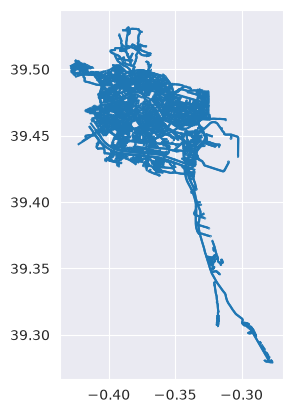

In [56]:
mapping_final.set_geometry(col="geometry_osm", inplace=True)
mapping_final.crs="EPSG:25830"
mapping_final.plot()

<Axes: >

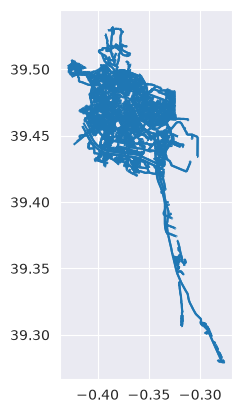

In [57]:
gdf_callejero_cleaned.plot()

In [58]:
print(mapping_final.crs)

EPSG:25830


In [ ]:

with open("graph_aws.pkl", "rb") as f:
    G = pickle.load(f)

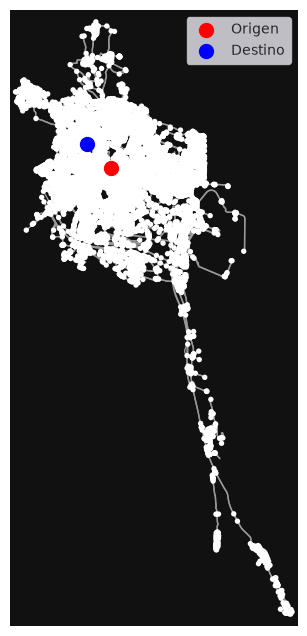

In [64]:
import matplotlib.pyplot as plt

fig, ax = ox.plot_graph(
    G,
    show=False,
    close=False
)

ax.scatter(
    [-0.3763],
    [39.4699],
    c="red",
    s=100,
    label="Origen"
)

ax.scatter(
    [-0.3900],
    [39.4800],
    c="blue",
    s=100,
    label="Destino"
)

ax.legend()

plt.show()

In [65]:
import networkx as nx
import osmnx as ox

print(G.graph["crs"])
print(G.number_of_nodes())
print(G.number_of_edges())

origin = ox.distance.nearest_nodes(
    G,
    X=-0.37660,
    Y=39.46975
)

destination = ox.distance.nearest_nodes(
    G,
    X=-0.35090,
    Y=39.45530
)

print(origin)
print(destination)

print(nx.has_path(G, origin, destination))
print(nx.shortest_path(G, origin, destination)[:10])

epsg:4326
8091
14571
35594370
96074337
True
[35594370, 25767448, 25767432, 25767365, 52748285, 52748811, 208232416, 208232422, 108325307, 108325510]
